# Langkah 1: Cek Struktur Folder & Hitung Gambar

In [1]:
import os
os.environ['KAGGLE_USERNAME'] = "muhammadhisyamkamil"
os.environ['KAGGLE_KEY'] = os.environ.get("KAGGLE_KEY", "YOUR_KAGGLE_API_KEY")

In [2]:
!kaggle kernels output elgafr/code3 -p /kaggle/working

Output file downloaded to /kaggle/working/best_densenet121_covid_4class.pth
Kernel log downloaded to /kaggle/working/code3.log 


In [3]:
!ls -la

total 36272
drwxr-xr-x 3 root root     4096 Dec 18 11:43 .
drwxr-xr-x 5 root root     4096 Dec 18 11:42 ..
-rw-r--r-- 1 root root 28452566 Dec 18 11:43 best_densenet121_covid_4class.pth
-rw-r--r-- 1 root root  8671554 Dec 18 11:43 code3.log
drwxr-xr-x 2 root root     4096 Dec 18 11:43 .virtual_documents


In [4]:
import os

# Definisikan path dataset baru
DATA_ROOT = '/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset'
CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

print(f"Memeriksa dataset di: {DATA_ROOT}\n")

total_images = 0
image_counts = {}

for category in CLASSES:
    # Path spesifik ke folder 'images' (mengabaikan folder 'masks')
    folder_path = os.path.join(DATA_ROOT, category, 'images')
    
    if os.path.exists(folder_path):
        # Menghitung file berekstensi .png, .jpg, .jpeg
        num_files = len([f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        image_counts[category] = num_files
        total_images += num_files
        print(f"Kelas '{category}': ditemukan {num_files} gambar.")
    else:
        print(f"WARNING: Folder tidak ditemukan: {folder_path}")

print(f"\nTotal semua gambar: {total_images}")

Memeriksa dataset di: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset

Kelas 'COVID': ditemukan 3616 gambar.
Kelas 'Lung_Opacity': ditemukan 6012 gambar.
Kelas 'Normal': ditemukan 10192 gambar.
Kelas 'Viral Pneumonia': ditemukan 1345 gambar.

Total semua gambar: 21165


In [5]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# --- 1. Konfigurasi Awal ---
DATA_ROOT = '/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset'
CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']
BATCH_SIZE = 32
IMAGE_SIZE = 224

# --- 2. Mengumpulkan Semua Path Gambar ---
all_image_paths = []
all_labels = []
class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASSES)}

for category in CLASSES:
    folder_path = os.path.join(DATA_ROOT, category, 'images')
    # Mengambil semua file png
    files = glob.glob(os.path.join(folder_path, '*.png'))
    
    for f in files:
        all_image_paths.append(f)
        all_labels.append(class_to_idx[category])

print(f"Total gambar dikumpulkan: {len(all_image_paths)}")

# --- 3. Membagi Data (Stratified Split) ---
# Split 1: Pisahkan Train (80%) dan Sisa (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    all_image_paths, all_labels, 
    test_size=0.2, 
    random_state=42, 
    stratify=all_labels # Penting karena data tidak seimbang
)

# Split 2: Pisahkan Sisa menjadi Val (10%) dan Test (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.5, 
    random_state=42, 
    stratify=y_temp
)

print(f"Data Train: {len(X_train)} gambar")
print(f"Data Val  : {len(X_val)} gambar")
print(f"Data Test : {len(X_test)} gambar")

# --- 4. Definisi Transformasi (Augmentasi) ---
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10), # Rotasi sedikit agar model lebih robust
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# --- 5. Custom Dataset Class ---
class CovidDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        # Load gambar dan convert ke RGB (wajib untuk model pre-trained ImageNet)
        try:
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
            return image, label
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            return torch.zeros((3, IMAGE_SIZE, IMAGE_SIZE)), label

# --- 6. Membuat DataLoader ---
train_dataset = CovidDataset(X_train, y_train, transform=data_transforms['train'])
val_dataset = CovidDataset(X_val, y_val, transform=data_transforms['val'])
test_dataset = CovidDataset(X_test, y_test, transform=data_transforms['test'])

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    'val':   DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2),
    'test':  DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
}

dataset_sizes = {'train': len(X_train), 'val': len(X_val), 'test': len(X_test)}
print("\nDataLoader siap! Batch size:", BATCH_SIZE)

Total gambar dikumpulkan: 21165
Data Train: 16932 gambar
Data Val  : 2116 gambar
Data Test : 2117 gambar

DataLoader siap! Batch size: 32


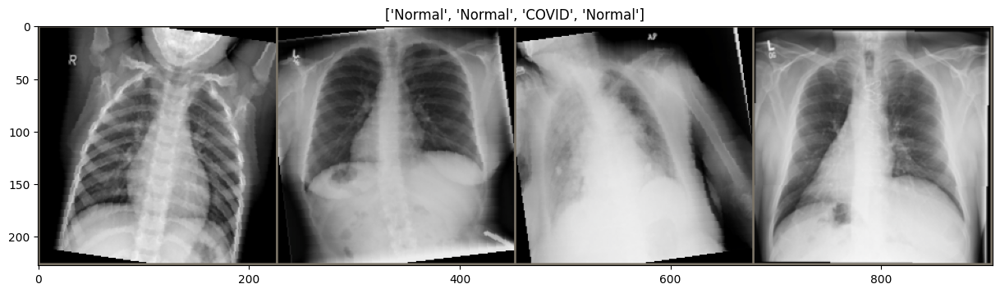

In [6]:
def imshow(inp, title=None):
    """Fungsi untuk menampilkan gambar tensor yang sudah dinormalisasi"""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean # Un-normalize
    inp = np.clip(inp, 0, 1)
    plt.figure(figsize=(15, 5))
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.pause(0.001)

# Ambil satu batch dari training
inputs, classes_idx = next(iter(dataloaders['train']))

# Buat grid gambar
import torchvision
out = torchvision.utils.make_grid(inputs[:4]) # Tampilkan 4 gambar pertama saja

imshow(out, title=[CLASSES[x] for x in classes_idx[:4]])

# Bagian 1: Import & Persiapan Data

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import glob
import copy
import time
from PIL import Image
from tqdm import tqdm

# --- 1. Konfigurasi ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = '/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset'
CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia'] # 4 Kelas
BATCH_SIZE = 32
IMAGE_SIZE = 224
EPOCHS = 10

print(f"Menggunakan perangkat: {DEVICE}")

# --- 2. Custom Dataset Class ---
class CovidDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

# --- 3. Load Data & Split ---
all_image_paths = []
all_labels = []
class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASSES)}

print("Mengumpulkan file gambar...")
for category in CLASSES:
    folder_path = os.path.join(DATA_ROOT, category, 'images')
    files = glob.glob(os.path.join(folder_path, '*.png'))
    for f in files:
        all_image_paths.append(f)
        all_labels.append(class_to_idx[category])

# Split: 80% Train, 10% Val, 10% Test
X_train, X_temp, y_train, y_temp = train_test_split(all_image_paths, all_labels, test_size=0.2, stratify=all_labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# --- 4. Transformasi & DataLoader ---
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ]),
    'test': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ]),
}

dataloaders = {
    'train': DataLoader(CovidDataset(X_train, y_train, transform=data_transforms['train']), batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    'val': DataLoader(CovidDataset(X_val, y_val, transform=data_transforms['val']), batch_size=BATCH_SIZE, shuffle=False, num_workers=2),
    'test': DataLoader(CovidDataset(X_test, y_test, transform=data_transforms['test']), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
}

dataset_sizes = {'train': len(X_train), 'val': len(X_val), 'test': len(X_test)}
print(f"Data siap: {dataset_sizes}")

Menggunakan perangkat: cuda
Mengumpulkan file gambar...
Data siap: {'train': 16932, 'val': 2116, 'test': 2117}


# Bagian 2: Definisi Model & Training (Dengan Visualisasi Loss/Acc)# 

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import copy
import matplotlib.pyplot as plt
import os  # Tambahan untuk cek file
from torchvision import models
from tqdm import tqdm # Progress bar

# --- 1. Konfigurasi Training ---
EPOCHS = 50        
PATIENCE = 5       
LEARNING_RATE = 1e-4
MODEL_SAVE_PATH = 'best_densenet121_covid_4class.pth'

# Pastikan DEVICE terdefinisi (biasanya dari cell sebelumnya), jika belum:
if 'DEVICE' not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Konfigurasi: Epochs={EPOCHS}, Patience={PATIENCE}, Device={DEVICE}")

# --- 2. Inisialisasi Model (DenseNet121) ---
print("Membangun arsitektur model...")
# Menggunakan bobot pretrained ImageNet
model_ft = models.densenet121(weights='DEFAULT')

# Mengubah layer terakhir (classifier) agar sesuai jumlah kelas kita (4 kelas)
num_ftrs = model_ft.classifier.in_features
# Pastikan variabel CLASSES sudah ada dari cell sebelumnya
if 'CLASSES' not in globals():
    CLASSES = ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia'] # Default fallback
    
model_ft.classifier = nn.Linear(num_ftrs, len(CLASSES)) 

# Pindahkan model ke GPU
model_ft = model_ft.to(DEVICE)

# Loss Function & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.Adam(model_ft.parameters(), lr=LEARNING_RATE)

# --- 3. Fungsi Training (dengan Early Stopping & History) ---
def train_model(model, criterion, optimizer, num_epochs=25, patience=5):
    since = time.time()

    # Simpan bobot awal sebagai bobot terbaik sementara
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    
    # Dictionary untuk menyimpan data visualisasi
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }
    
    patience_counter = 0 # Penghitung untuk early stopping

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Setiap epoch punya fase training dan validasi
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Mode training
            else:
                model.eval()   # Mode evaluasi

            running_loss = 0.0
            running_corrects = 0

            # Iterasi data
            for inputs, labels in tqdm(dataloaders[phase], desc=f"Fase {phase.capitalize()}", leave=False):
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)

                # Zero parameter gradients
                optimizer.zero_grad()

                # Forward
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # Backward + Optimize hanya saat fase training
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # Statistik
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            # Hitung rata-rata loss dan akurasi epoch ini
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            # Simpan ke history
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Deep copy model jika performa membaik (Hanya di fase Val)
            if phase == 'val':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    patience_counter = 0 
                    print(" Akurasi validasi meningkat! Menyimpan model sementara...")
                else:
                    patience_counter += 1 
                    print(f" Tidak ada peningkatan. Patience: {patience_counter}/{patience}")

        # Cek Early Stopping setelah fase Val selesai
        if patience_counter >= patience:
            print(f"\n⏹ Early Stopping aktif! Training berhenti di epoch {epoch+1}.")
            break

    time_elapsed = time.time() - since
    print(f'\nTraining selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Akurasi Validasi Terbaik: {best_acc:.4f}')

    # Load bobot terbaik ke model
    model.load_state_dict(best_model_wts)
    return model, history

# --- 4. VISUALISASI LOSS & ACCURACY (Definisi Fungsi) ---
def plot_training_results(history):
    acc = history['train_acc']
    val_acc = history['val_acc']
    loss = history['train_loss']
    val_loss = history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(15, 5))
    
    # Grafik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid(True)

    # Grafik Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# --- 5. LOGIKA UTAMA: LOAD OR TRAIN ---

if os.path.exists(MODEL_SAVE_PATH):
    print(f"\n File model ditemukan: '{MODEL_SAVE_PATH}'")
    print("⏳ Memuat model yang sudah ada...")
    
    # Load state dict dengan map_location agar aman (GPU/CPU)
    state_dict = torch.load(MODEL_SAVE_PATH, map_location=DEVICE)
    model_ft.load_state_dict(state_dict)
    
    print(" Model berhasil dimuat! Melewati proses training.")
    print("Catatan: Grafik training tidak ditampilkan karena model dimuat dari file.")
    
else:
    print(f"\n File model '{MODEL_SAVE_PATH}' tidak ditemukan.")
    print(" Memulai proses training baru...")
    
    # Jalankan fungsi training
    model_ft, history = train_model(
        model_ft, 
        criterion, 
        optimizer_ft, 
        num_epochs=EPOCHS, 
        patience=PATIENCE
    )
    
    # Simpan model setelah training selesai
    torch.save(model_ft.state_dict(), MODEL_SAVE_PATH)
    print(f"\n Model baru berhasil disimpan ke: {MODEL_SAVE_PATH}")
    
    # Tampilkan grafik hanya jika baru saja training
    plot_training_results(history)

Konfigurasi: Epochs=50, Patience=5, Device=cuda
Membangun arsitektur model...


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 200MB/s]



 File model ditemukan: 'best_densenet121_covid_4class.pth'
⏳ Memuat model yang sudah ada...
 Model berhasil dimuat! Melewati proses training.
Catatan: Grafik training tidak ditampilkan karena model dimuat dari file.


# Bagian 3: Adversarial Attacks (PGD & FGSM)

In [9]:
# Konstanta Normalisasi (Tensor)
MEAN_TENSOR = torch.tensor(norm_mean, device=DEVICE).view(1, 3, 1, 1)
STD_TENSOR = torch.tensor(norm_std, device=DEVICE).view(1, 3, 1, 1)

# --- 1. Fungsi FGSM ---
def fgsm_attack(model, images, labels, epsilon):
    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    images.requires_grad = True
    
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    model.zero_grad()
    loss.backward()
    
    data_grad = images.grad.data
    # Rumus FGSM: x_adv = x + epsilon * sign(grad)
    sign_data_grad = data_grad.sign()
    
    # Kita harus menormalisasi perturbation karena input model ter-normalisasi
    # epsilon asli (misal 0.1/255) adalah dalam pixel space [0,1], 
    # jadi kita bagi dengan STD untuk masuk ke normalized space
    normalized_epsilon = epsilon / STD_TENSOR
    
    perturbed_image = images + normalized_epsilon * sign_data_grad
    # Clamping tidak sederhana karena data ter-normalisasi, tapi untuk FGSM cepat biasanya diabaikan
    # atau kita lakukan clamp manual di normalized space (optional tapi recommended untuk PGD)
    return perturbed_image

# --- 2. Fungsi PGD (Iterative FGSM) ---
def pgd_attack(model, images, labels, eps, alpha, steps):
    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    original_images = images.clone().detach()
    
    # Ubah parameter pixel space ke normalized space
    eps_norm = eps / STD_TENSOR
    alpha_norm = alpha / STD_TENSOR
    
    # Random start
    dataset_min = (0 - MEAN_TENSOR) / STD_TENSOR
    dataset_max = (1 - MEAN_TENSOR) / STD_TENSOR
    
    perturbation = torch.empty_like(images).uniform_(-1, 1) * eps_norm
    adv_images = torch.clamp(images + perturbation, min=dataset_min, max=dataset_max).detach()
    
    for _ in range(steps):
        adv_images.requires_grad = True
        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)
        
        grad = torch.autograd.grad(loss, adv_images, retain_graph=False, create_graph=False)[0]
        
        adv_images = adv_images.detach() + alpha_norm * grad.sign()
        
        # Proyeksi (Clip perturbation agar tetap dalam range epsilon)
        delta = torch.clamp(adv_images - original_images, min=-eps_norm, max=eps_norm)
        adv_images = torch.clamp(original_images + delta, min=dataset_min, max=dataset_max).detach()
        
    return adv_images

print("Fungsi Attack siap.")

Fungsi Attack siap.


# Bagian 4: Evaluasi Lengkap PGD (Clean vs Adversarial)


--- Laporan: Original Test Set ---
                 precision    recall  f1-score   support

          COVID     0.9914    0.9586    0.9747       362
   Lung_Opacity     0.9566    0.9153    0.9355       602
         Normal     0.9368    0.9745    0.9553      1019
Viral Pneumonia     0.9847    0.9627    0.9736       134

       accuracy                         0.9542      2117
      macro avg     0.9674    0.9528    0.9598      2117
   weighted avg     0.9548    0.9542    0.9541      2117



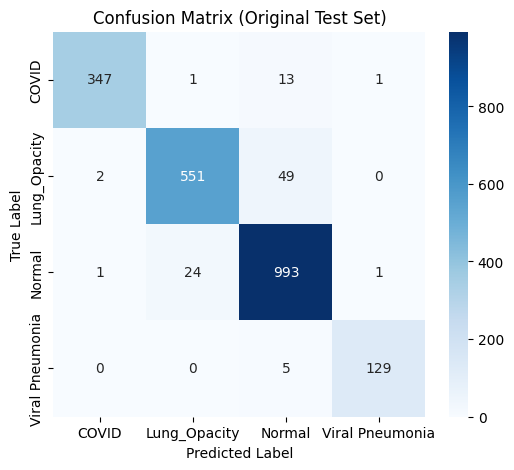


Membuat Adversarial Test Set (ini memakan waktu)...


100%|██████████| 67/67 [01:22<00:00,  1.23s/it]



--- Laporan: PGD Adversarial Test Set ---
                 precision    recall  f1-score   support

          COVID     0.3759    0.6022    0.4628       362
   Lung_Opacity     0.3794    0.3555    0.3671       602
         Normal     0.7344    0.5888    0.6536      1019
Viral Pneumonia     0.6987    0.8134    0.7517       134

       accuracy                         0.5390      2117
      macro avg     0.5471    0.5900    0.5588      2117
   weighted avg     0.5699    0.5390    0.5457      2117



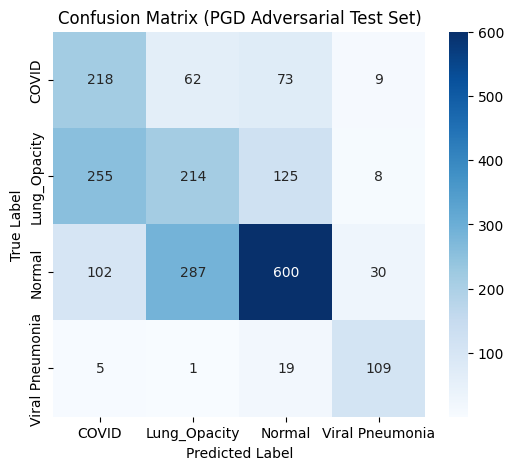


=== Tabel Summary PGD (Detail) ===
  Attack Type   Epsilon  Success Rate Clean (%)  Accuracy on Adv (%)  \
0         PGD  0.000392               95.418044            53.897024   

   Attack Success Rate (ASR %)  
0                    46.102976  


In [10]:
# %% [markdown]
# # Bagian 4: Evaluasi Lengkap PGD (Clean vs Adversarial)
# %%
import pandas as pd  # Tambah import pandas untuk tabel

def evaluate_dataset(model, dataloader, dataset_name="Dataset"):
    model.eval()
    all_preds = []
    all_labels = []
   
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
           
    # Hitung accuracy global
    correct = sum(p == l for p, l in zip(all_preds, all_labels))
    total = len(all_labels)
    accuracy = 100 * correct / total if total > 0 else 0
   
    print(f"\n--- Laporan: {dataset_name} ---")
    print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))
   
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(f'Confusion Matrix ({dataset_name})')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
   
    # Kembalikan metrics untuk tabel
    return {
        'accuracy': accuracy,
        'cm': cm,
        'all_preds': all_preds,
        'all_labels': all_labels
    }

# 1. Evaluasi Data Asli (Clean)
metrics_clean_pgd = evaluate_dataset(model_ft, dataloaders['test'], "Original Test Set")

# 2. Membuat Dataset Adversarial (PGD)
print("\nMembuat Adversarial Test Set (ini memakan waktu)...")
adv_images_list = []
adv_labels_list = []
eps_pgd = 0.1/255
for inputs, labels in tqdm(dataloaders['test']):
    # Generate PGD Attack
    adv_inputs = pgd_attack(model_ft, inputs, labels, eps=eps_pgd, alpha=2/255, steps=10)
    adv_images_list.append(adv_inputs.cpu())
    adv_labels_list.append(labels)
# Gabung jadi DataLoader baru
adv_images_tensor = torch.cat(adv_images_list)
adv_labels_tensor = torch.cat(adv_labels_list)
adv_dataset = TensorDataset(adv_images_tensor, adv_labels_tensor)
adv_loader = DataLoader(adv_dataset, batch_size=BATCH_SIZE, shuffle=False)
# 3. Evaluasi Data Adversarial
metrics_adv_pgd = evaluate_dataset(model_ft, adv_loader, "PGD Adversarial Test Set")

# Hitung ASR (Attack Success Rate): proporsi sampel yang berubah dari benar ke salah
asr_pgd = 100 - metrics_adv_pgd['accuracy']  # Karena attack targeted, ASR = 1 - acc_adv

# Tabel detail PGD
pgd_table = pd.DataFrame({
    'Attack Type': ['PGD'],
    'Epsilon': [eps_pgd],
    'Success Rate Clean (%)': [metrics_clean_pgd['accuracy']],
    'Accuracy on Adv (%)': [metrics_adv_pgd['accuracy']],
    'Attack Success Rate (ASR %)': [asr_pgd]
})
print("\n=== Tabel Summary PGD (Detail) ===")
print(pgd_table)

# Bagian 5: Evaluasi Lengkap FGSM (Clean vs Adversarial)


[Bagian 5] Membuat & Mengevaluasi FGSM Attack (Epsilon=0.1/255)...


Generating FGSM: 100%|██████████| 67/67 [00:13<00:00,  4.93it/s]



HASIL EVALUASI: FGSM Attack Test Set
Akurasi: 59.28%

Classification Report:
                 precision    recall  f1-score   support

          COVID     0.4844    0.5138    0.4987       362
   Lung_Opacity     0.4576    0.4568    0.4572       602
         Normal     0.6989    0.6742    0.6863      1019
Viral Pneumonia     0.7181    0.7985    0.7562       134

       accuracy                         0.5928      2117
      macro avg     0.5897    0.6108    0.5996      2117
   weighted avg     0.5948    0.5928    0.5935      2117



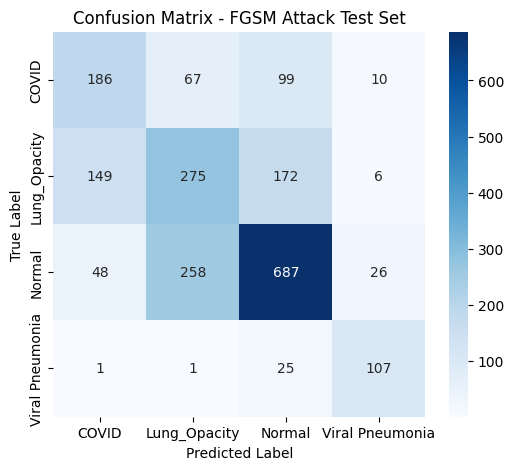


=== Tabel Summary FGSM (Detail) ===
  Attack Type   Epsilon  Success Rate Clean (%)  Accuracy on Adv (%)  \
0        FGSM  0.000392               95.418044            59.282003   

   Attack Success Rate (ASR %)  
0                    40.717997  


In [11]:
# %% [markdown]
# # Bagian 5: Evaluasi Lengkap FGSM (Clean vs Adversarial)
# %%
# --- BAGIAN 5: EVALUASI KHUSUS FGSM ---
# (Jalankan ini setelah Bagian 4 selesai)
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm
import pandas as pd  # Tambah import pandas untuk tabel

# Kita definisikan ulang fungsi evaluasi agar cell ini bisa berjalan mandiri
def evaluate_dataset_fgsm(model, dataloader, dataset_name="Dataset"):
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
   
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(DEVICE)
            labels = labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
           
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
           
            total += labels.size(0)
            correct += (preds == labels).sum().item()
           
    acc = 100 * correct / total
    print(f"\n{'='*20}")
    print(f"HASIL EVALUASI: {dataset_name}")
    print(f"{'='*20}")
    print(f"Akurasi: {acc:.2f}%")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))
   
    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(f'Confusion Matrix - {dataset_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
   
    # Kembalikan metrics
    return {
        'accuracy': acc,
        'cm': cm,
        'all_preds': all_preds,
        'all_labels': all_labels
    }

# --- MULAI PROSES FGSM ---
print("\n[Bagian 5] Membuat & Mengevaluasi FGSM Attack (Epsilon=0.1/255)...")
fgsm_images_list = []
fgsm_labels_list = []
eps_fgsm = 0.1/255
# Loop generate data FGSM
for inputs, labels in tqdm(dataloaders['test'], desc="Generating FGSM"):
    # Generate FGSM (Menggunakan fungsi fgsm_attack dari Bagian 3)
    adv_inputs = fgsm_attack(model_ft, inputs, labels, epsilon=eps_fgsm)
   
    fgsm_images_list.append(adv_inputs.cpu())
    fgsm_labels_list.append(labels)
# Gabungkan menjadi Dataset & DataLoader baru
fgsm_data = torch.cat(fgsm_images_list)
fgsm_labels = torch.cat(fgsm_labels_list)
fgsm_loader = DataLoader(TensorDataset(fgsm_data, fgsm_labels), batch_size=BATCH_SIZE, shuffle=False)
# Evaluasi
metrics_adv_fgsm = evaluate_dataset_fgsm(model_ft, fgsm_loader, "FGSM Attack Test Set")

# Hitung ASR untuk FGSM
asr_fgsm = 100 - metrics_adv_fgsm['accuracy']

# Tabel detail FGSM
fgsm_table = pd.DataFrame({
    'Attack Type': ['FGSM'],
    'Epsilon': [eps_fgsm],
    'Success Rate Clean (%)': [metrics_clean_pgd['accuracy']],  # Reuse clean metrics dari PGD (sama saja)
    'Accuracy on Adv (%)': [metrics_adv_fgsm['accuracy']],
    'Attack Success Rate (ASR %)': [asr_fgsm]
})
print("\n=== Tabel Summary FGSM (Detail) ===")
print(fgsm_table)

In [12]:
# %% [markdown]
# # Bagian 5.5: Summary Tabel Gabungan FGSM & PGD
# %%
# Gabungkan tabel FGSM dan PGD menjadi satu
combined_table = pd.concat([pgd_table, fgsm_table], ignore_index=True)
print("\n=== Tabel Summary Gabungan (FGSM & PGD) ===")
print(combined_table)


=== Tabel Summary Gabungan (FGSM & PGD) ===
  Attack Type   Epsilon  Success Rate Clean (%)  Accuracy on Adv (%)  \
0         PGD  0.000392               95.418044            53.897024   
1        FGSM  0.000392               95.418044            59.282003   

   Attack Success Rate (ASR %)  
0                    46.102976  
1                    40.717997  


# Bagian 6: Visualisasi Grad-CAM (Clean vs Adv)

In [13]:
!pip install grad-cam


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 60.1 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.8 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of mkl-fft to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-random to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-umath to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 111.9 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 87.6 MB/s eta 0:00:00:

Mencari sampel representatif untuk setiap kelas...

Memproses Visualisasi Grad-CAM (Clean vs FGSM vs PGD)...


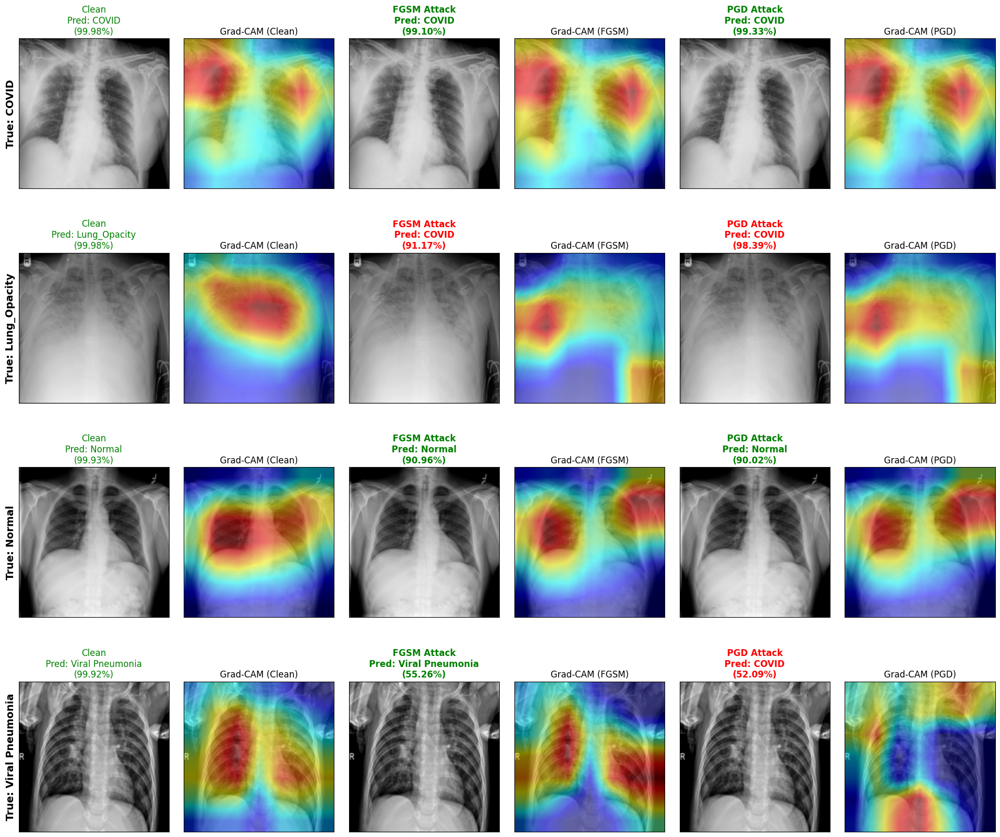

In [14]:
# --- BAGIAN 6: VISUALISASI GRAD-CAM LENGKAP (Clean vs FGSM vs PGD) ---

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# 1. Helper untuk Denormalisasi Gambar (Tensor -> Numpy Image)
def denormalize_image(tensor):
    """Mengembalikan tensor (C,H,W) ke numpy (H,W,C) range [0,1] untuk plotting"""
    # Menggunakan mean/std yang sama dengan saat training
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    
    # Denormalize: img * std + mean
    img = img * std + mean
    return np.clip(img, 0, 1)

# 2. Helper untuk mengambil 1 sampel unik per kelas
def get_one_sample_per_class(dataloader, classes):
    samples = {}
    found_count = 0
    target_count = len(classes)
    
    print("Mencari sampel representatif untuk setiap kelas...")
    
    for inputs, labels in dataloader:
        for i in range(len(labels)):
            label_idx = labels[i].item()
            if label_idx not in samples:
                samples[label_idx] = inputs[i]
                found_count += 1
            
            if found_count == target_count:
                break
        if found_count == target_count:
            break
            
    # Urutkan berdasarkan index kelas (0, 1, 2, 3)
    sorted_samples = [samples[i] for i in range(target_count)]
    return sorted_samples

# 3. Fungsi Utama Visualisasi
def visualize_complete_gradcam(model, loader):
    model.eval()
    
    # Target Layer DenseNet121 (Layer feature terakhir)
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    # Ambil 1 gambar per kelas
    sample_images = get_one_sample_per_class(loader, CLASSES)
    
    # Setup Plot: 4 Baris (Kelas) x 6 Kolom (Clean, CAM, FGSM, CAM, PGD, CAM)
    rows = len(CLASSES)
    cols = 6
    fig, axs = plt.subplots(rows, cols, figsize=(24, 5 * rows))
    plt.subplots_adjust(wspace=0.1, hspace=0.3)
    
    print("\nMemproses Visualisasi Grad-CAM (Clean vs FGSM vs PGD)...")
    
    for i, img_tensor in enumerate(sample_images):
        img_tensor = img_tensor.unsqueeze(0).to(DEVICE) # Tambah batch dim
        label_idx = i # Karena sample_images sudah urut index
        true_label = CLASSES[label_idx]
        
        # --- A. CLEAN PASS ---
        out_clean = model(img_tensor)
        pred_clean_idx = out_clean.argmax(dim=1).item()
        prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
        cam_clean = cam(input_tensor=img_tensor, targets=None)[0] # Targets=None ambil top prediction
        
        # --- B. FGSM ATTACK ---
        adv_fgsm = fgsm_attack(model, img_tensor, torch.tensor([label_idx]), epsilon=0.1/255)
        out_fgsm = model(adv_fgsm)
        pred_fgsm_idx = out_fgsm.argmax(dim=1).item()
        prob_fgsm = F.softmax(out_fgsm, dim=1)[0][pred_fgsm_idx].item()
        cam_fgsm = cam(input_tensor=adv_fgsm, targets=None)[0]
        
        # --- C. PGD ATTACK ---
        adv_pgd = pgd_attack(model, img_tensor, torch.tensor([label_idx]), eps=0.1/255, alpha=2/255, steps=10)
        out_pgd = model(adv_pgd)
        pred_pgd_idx = out_pgd.argmax(dim=1).item()
        prob_pgd = F.softmax(out_pgd, dim=1)[0][pred_pgd_idx].item()
        cam_pgd = cam(input_tensor=adv_pgd, targets=None)[0]
        
        # --- D. PERSIAPAN GAMBAR (Denormalize) ---
        rgb_clean = denormalize_image(img_tensor[0])
        rgb_fgsm = denormalize_image(adv_fgsm[0])
        rgb_pgd = denormalize_image(adv_pgd[0])
        
        viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
        viz_fgsm = show_cam_on_image(rgb_fgsm, cam_fgsm, use_rgb=True)
        viz_pgd = show_cam_on_image(rgb_pgd, cam_pgd, use_rgb=True)
        
        # --- E. PLOTTING ---
        
        # 1. Clean Image
        axs[i, 0].imshow(rgb_clean)
        axs[i, 0].set_ylabel(f"True: {true_label}", fontsize=14, fontweight='bold')
        axs[i, 0].set_title(f"Clean\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.2%})", color='green' if pred_clean_idx==label_idx else 'red')
        
        # 2. Clean CAM
        axs[i, 1].imshow(viz_clean)
        axs[i, 1].set_title("Grad-CAM (Clean)")
        
        # 3. FGSM Image
        axs[i, 2].imshow(rgb_fgsm)
        axs[i, 2].set_title(f"FGSM Attack\nPred: {CLASSES[pred_fgsm_idx]}\n({prob_fgsm:.2%})", color='green' if pred_fgsm_idx==label_idx else 'red', fontweight='bold')
        
        # 4. FGSM CAM
        axs[i, 3].imshow(viz_fgsm)
        axs[i, 3].set_title("Grad-CAM (FGSM)")
        
        # 5. PGD Image
        axs[i, 4].imshow(rgb_pgd)
        axs[i, 4].set_title(f"PGD Attack\nPred: {CLASSES[pred_pgd_idx]}\n({prob_pgd:.2%})", color='green' if pred_pgd_idx==label_idx else 'red', fontweight='bold')
        
        # 6. PGD CAM
        axs[i, 5].imshow(viz_pgd)
        axs[i, 5].set_title("Grad-CAM (PGD)")
        
        # Matikan axis ticks
        for j in range(cols):
            axs[i, j].set_xticks([])
            axs[i, j].set_yticks([])

    plt.show()

# --- Jalankan Fungsi ---
visualize_complete_gradcam(model_ft, dataloaders['test'])

# BAGIAN 7: VISUALISASI GRAD-CAM 5 SAMPEL PER KELAS

Memulai Visualisasi Detail (5 Sampel per Kelas)...

Processing Class: COVID...


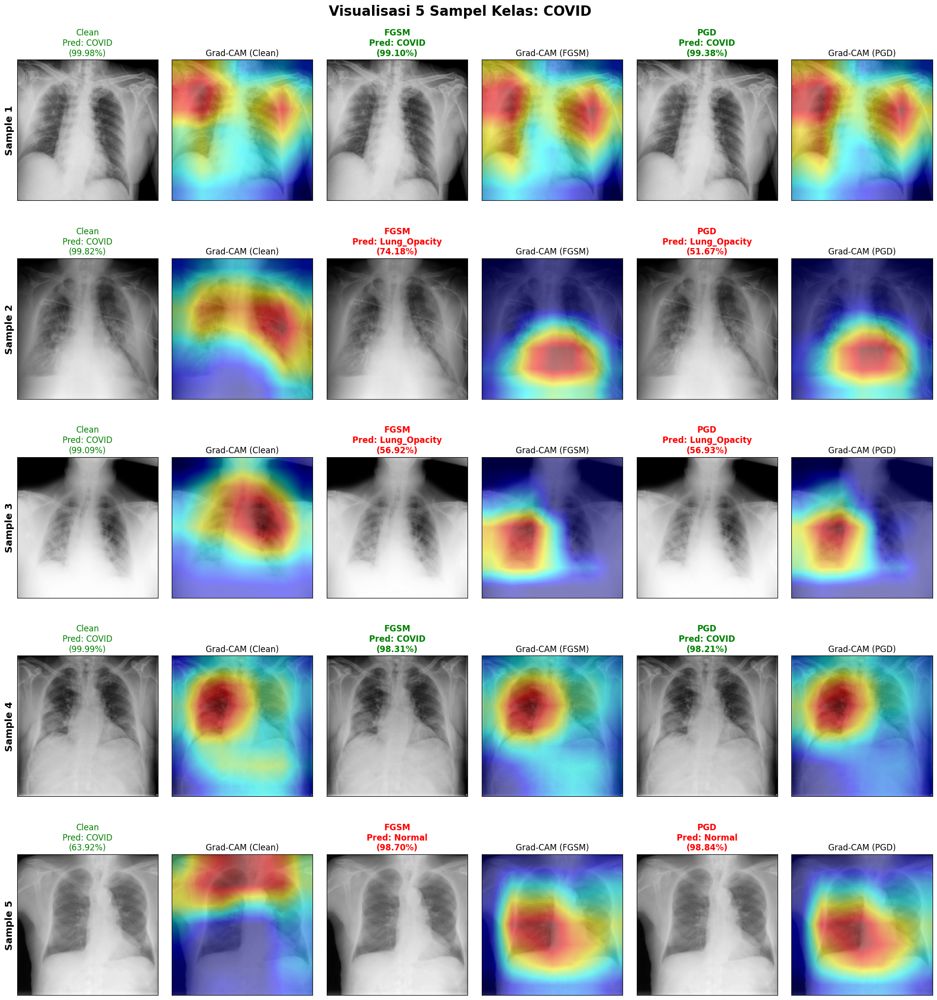


Processing Class: Lung_Opacity...


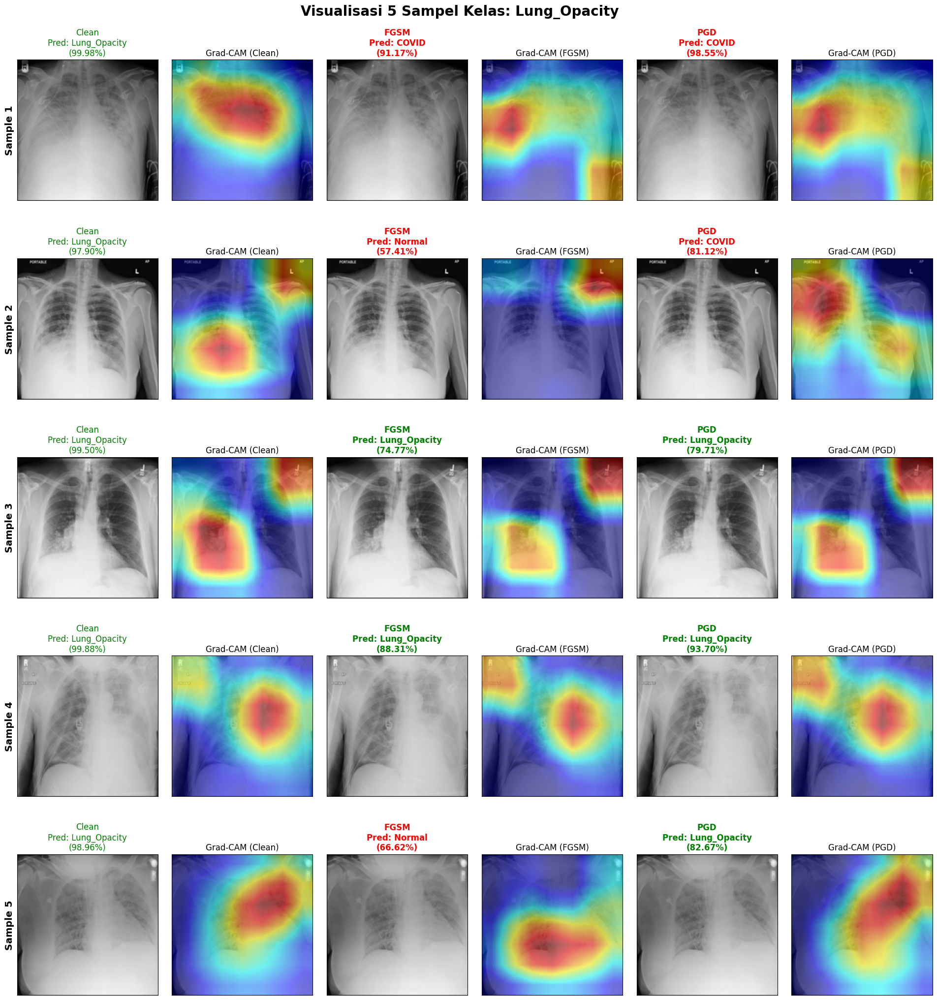


Processing Class: Normal...


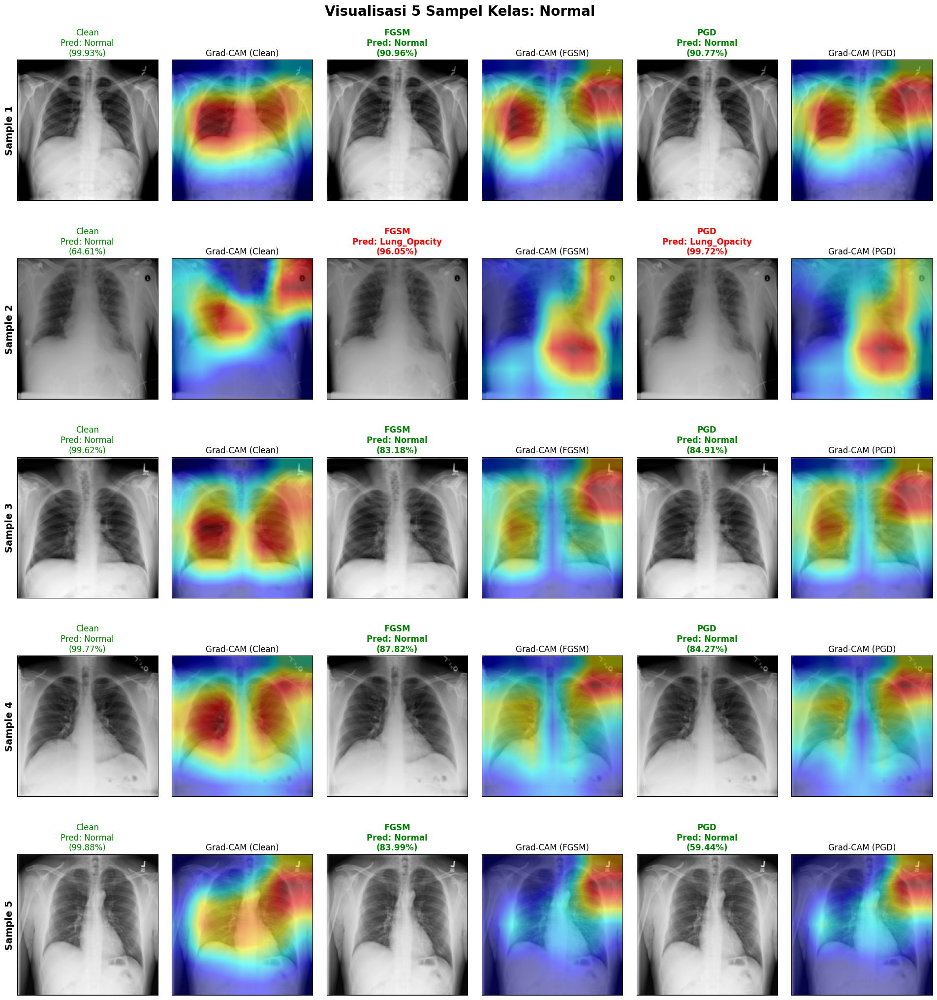


Processing Class: Viral Pneumonia...


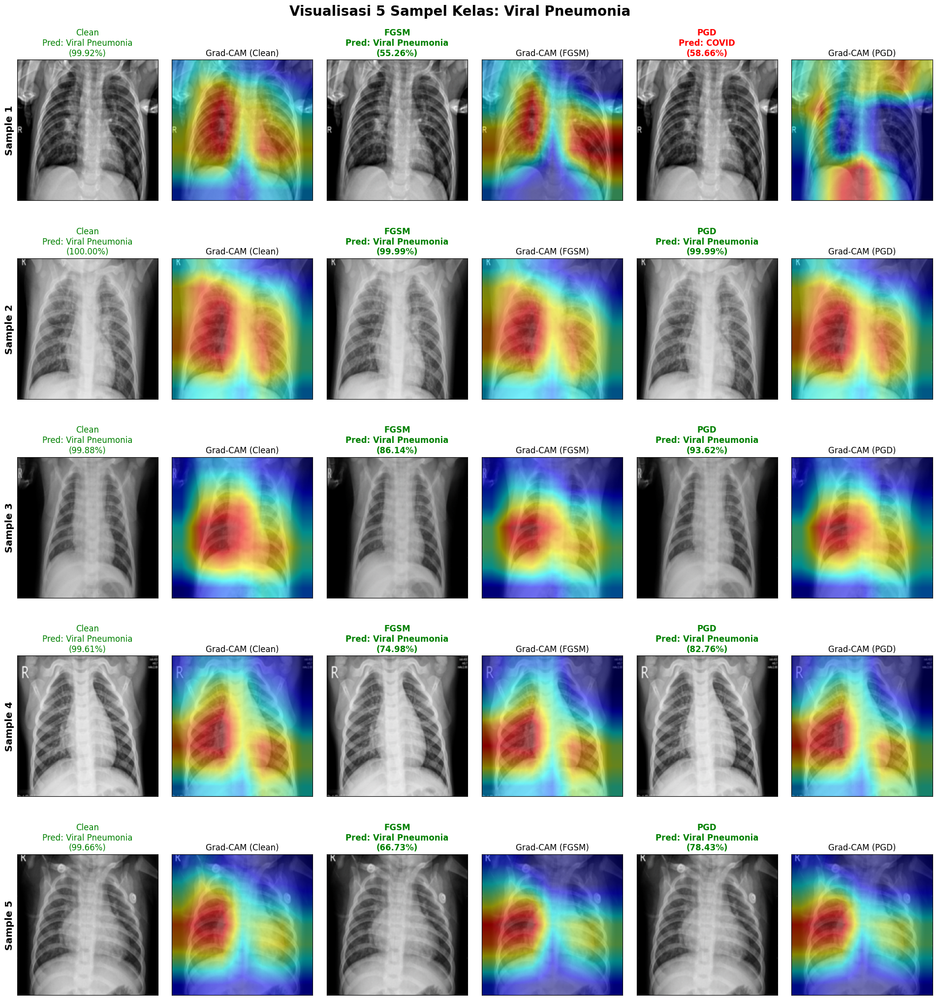

In [15]:
# --- BAGIAN 7: VISUALISASI GRAD-CAM 5 SAMPEL PER KELAS ---

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# 1. Helper: Ambil N sampel spesifik untuk satu kelas tertentu
def get_samples_for_specific_class(dataloader, target_class_idx, num_samples=5):
    collected_samples = []
    
    for inputs, labels in dataloader:
        for i in range(len(labels)):
            if labels[i].item() == target_class_idx:
                collected_samples.append(inputs[i])
            
            if len(collected_samples) >= num_samples:
                return collected_samples
    return collected_samples

# 2. Fungsi Visualisasi Satu Blok Kelas (Isi 5 Baris)
def visualize_class_block(model, class_name, class_idx, samples):
    model.eval()
    
    # Target Layer
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_samples = len(samples)
    
    # Setup Plot: N Baris x 6 Kolom
    fig, axs = plt.subplots(num_samples, 6, figsize=(24, 5 * num_samples))
    plt.suptitle(f"Visualisasi 5 Sampel Kelas: {class_name}", fontsize=20, fontweight='bold', y=0.92)
    plt.subplots_adjust(wspace=0.1, hspace=0.3)
    
    for i, img_tensor in enumerate(samples):
        img_tensor = img_tensor.unsqueeze(0).to(DEVICE)
        
        # --- A. CLEAN PASS ---
        out_clean = model(img_tensor)
        pred_clean_idx = out_clean.argmax(dim=1).item()
        prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
        cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
        
        # --- B. FGSM ATTACK ---
        adv_fgsm = fgsm_attack(model, img_tensor, torch.tensor([class_idx]), epsilon=0.1/255)
        out_fgsm = model(adv_fgsm)
        pred_fgsm_idx = out_fgsm.argmax(dim=1).item()
        prob_fgsm = F.softmax(out_fgsm, dim=1)[0][pred_fgsm_idx].item()
        cam_fgsm = cam(input_tensor=adv_fgsm, targets=None)[0]
        
        # --- C. PGD ATTACK ---
        adv_pgd = pgd_attack(model, img_tensor, torch.tensor([class_idx]), eps=0.1/255, alpha=2/255, steps=10)
        out_pgd = model(adv_pgd)
        pred_pgd_idx = out_pgd.argmax(dim=1).item()
        prob_pgd = F.softmax(out_pgd, dim=1)[0][pred_pgd_idx].item()
        cam_pgd = cam(input_tensor=adv_pgd, targets=None)[0]
        
        # --- D. VISUALISASI ---
        rgb_clean = denormalize_image(img_tensor[0])
        rgb_fgsm = denormalize_image(adv_fgsm[0])
        rgb_pgd = denormalize_image(adv_pgd[0])
        
        viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
        viz_fgsm = show_cam_on_image(rgb_fgsm, cam_fgsm, use_rgb=True)
        viz_pgd = show_cam_on_image(rgb_pgd, cam_pgd, use_rgb=True)
        
        # --- E. PLOTTING ROW ---
        # 1. Clean
        axs[i, 0].imshow(rgb_clean)
        axs[i, 0].set_ylabel(f"Sample {i+1}", fontsize=14, fontweight='bold')
        axs[i, 0].set_title(f"Clean\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.2%})", color='green' if pred_clean_idx==class_idx else 'red')
        
        # 2. Clean CAM
        axs[i, 1].imshow(viz_clean)
        axs[i, 1].set_title("Grad-CAM (Clean)")
        
        # 3. FGSM
        axs[i, 2].imshow(rgb_fgsm)
        axs[i, 2].set_title(f"FGSM\nPred: {CLASSES[pred_fgsm_idx]}\n({prob_fgsm:.2%})", color='green' if pred_fgsm_idx==class_idx else 'red', fontweight='bold')
        
        # 4. FGSM CAM
        axs[i, 3].imshow(viz_fgsm)
        axs[i, 3].set_title("Grad-CAM (FGSM)")
        
        # 5. PGD
        axs[i, 4].imshow(rgb_pgd)
        axs[i, 4].set_title(f"PGD\nPred: {CLASSES[pred_pgd_idx]}\n({prob_pgd:.2%})", color='green' if pred_pgd_idx==class_idx else 'red', fontweight='bold')
        
        # 6. PGD CAM
        axs[i, 5].imshow(viz_pgd)
        axs[i, 5].set_title("Grad-CAM (PGD)")
        
        # Matikan axis
        for j in range(6):
            axs[i, j].set_xticks([])
            axs[i, j].set_yticks([])
            if j != 0: axs[i, j].set_ylabel("") # Hanya kolom pertama yang punya label y

    plt.show()

# --- 3. LOOP UTAMA: JALANKAN UNTUK SETIAP KELAS ---
print("Memulai Visualisasi Detail (5 Sampel per Kelas)...")

for idx, class_name in enumerate(CLASSES):
    print(f"\nProcessing Class: {class_name}...")
    
    # Ambil 5 sampel untuk kelas ini
    samples = get_samples_for_specific_class(dataloaders['test'], idx, num_samples=5)
    
    if len(samples) < 5:
        print(f"Peringatan: Hanya ditemukan {len(samples)} sampel untuk kelas {class_name}")
    
    # Tampilkan Grid
    visualize_class_block(model_ft, class_name, idx, samples)

# BAGIAN 8: VISUALISASI GRAD-CAM + BENTUK NOISE (8 KOLOM)

Memulai Visualisasi Lengkap dengan Bentuk Noise...

Processing Class: COVID...


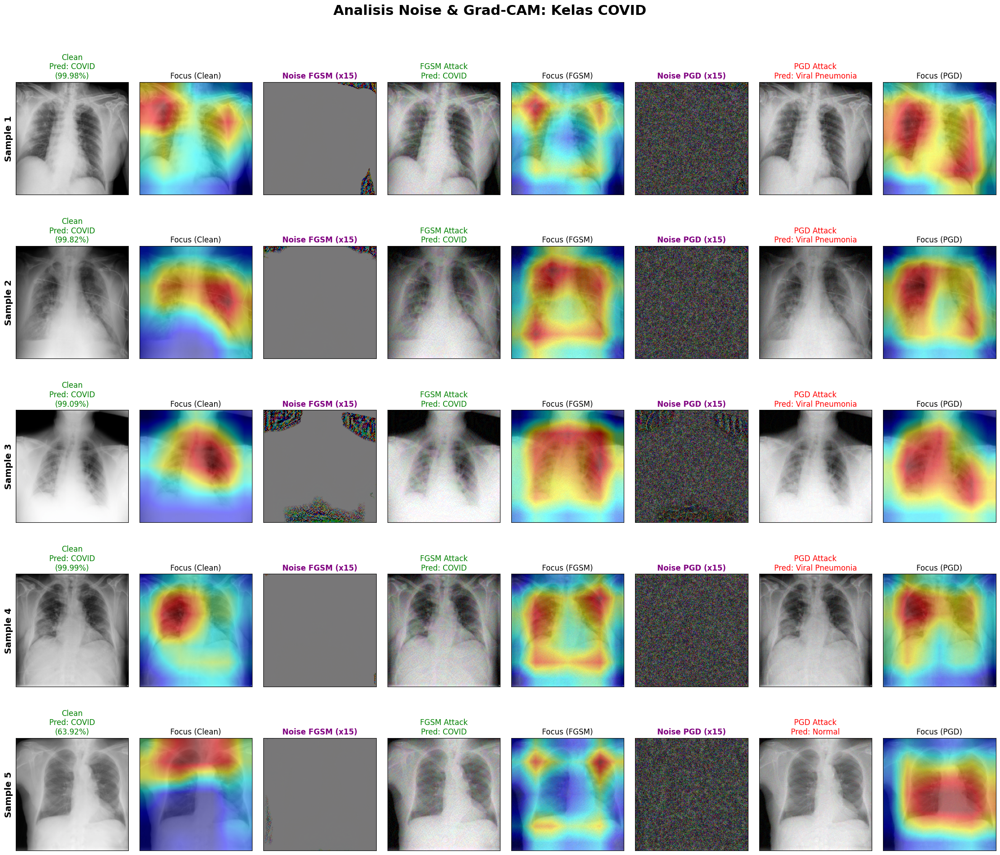


Processing Class: Lung_Opacity...


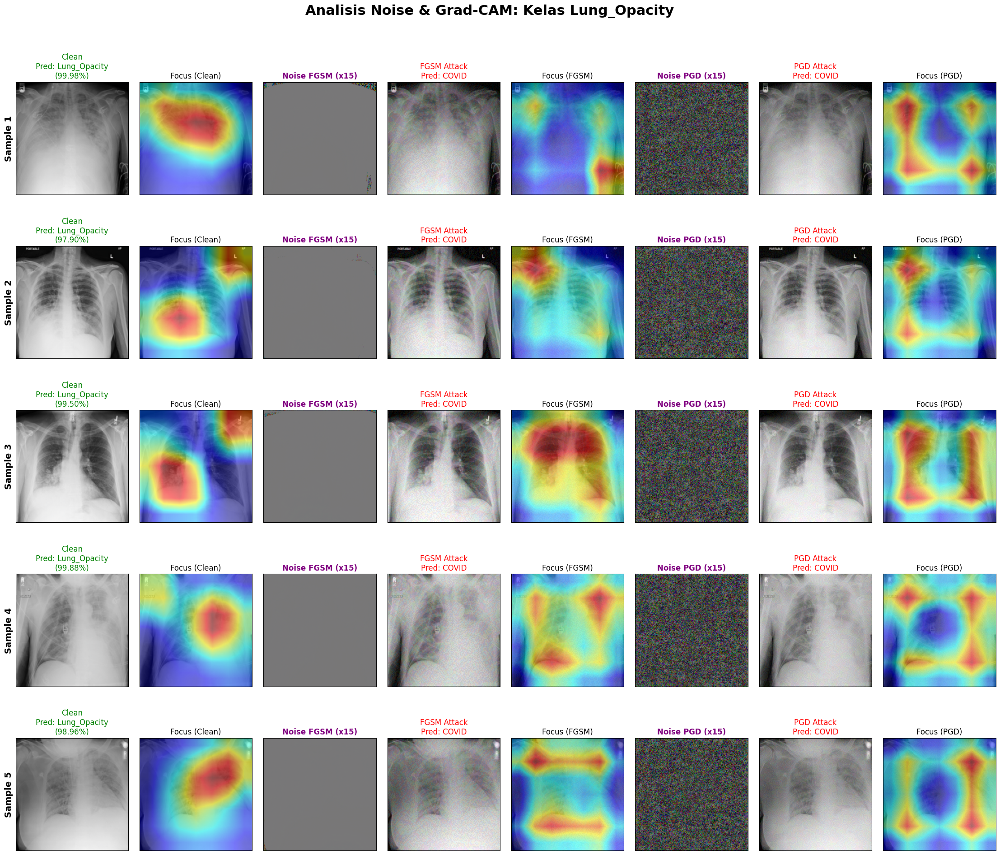


Processing Class: Normal...


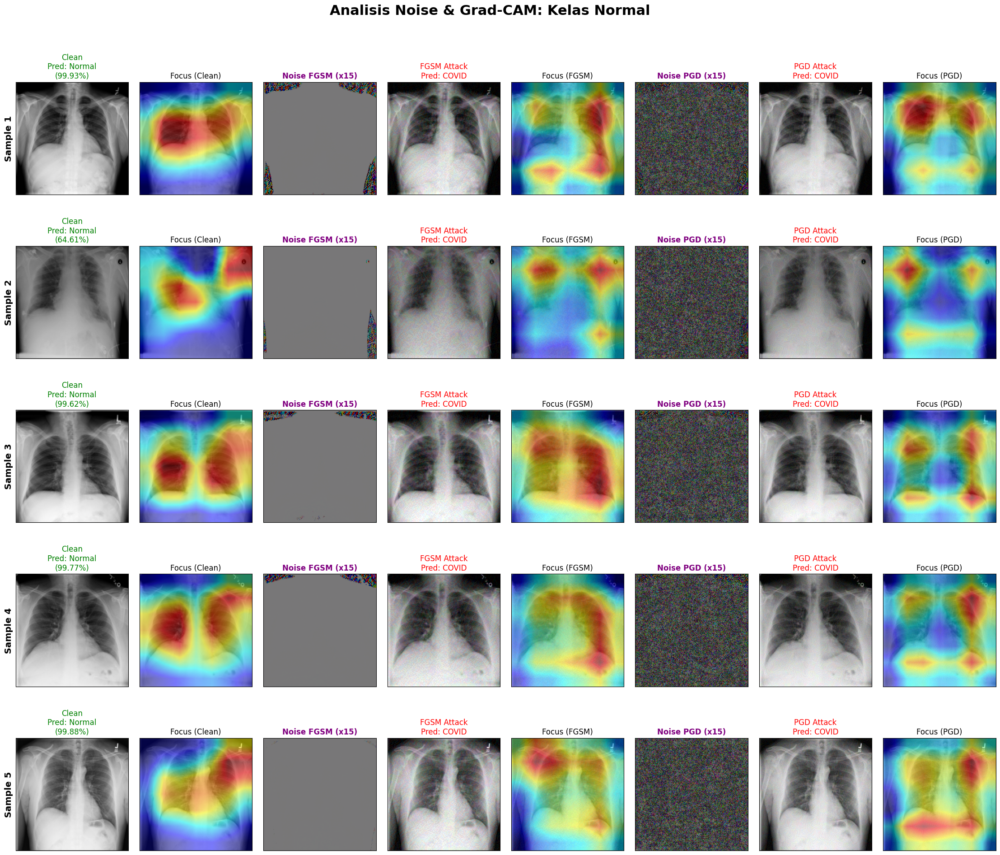


Processing Class: Viral Pneumonia...


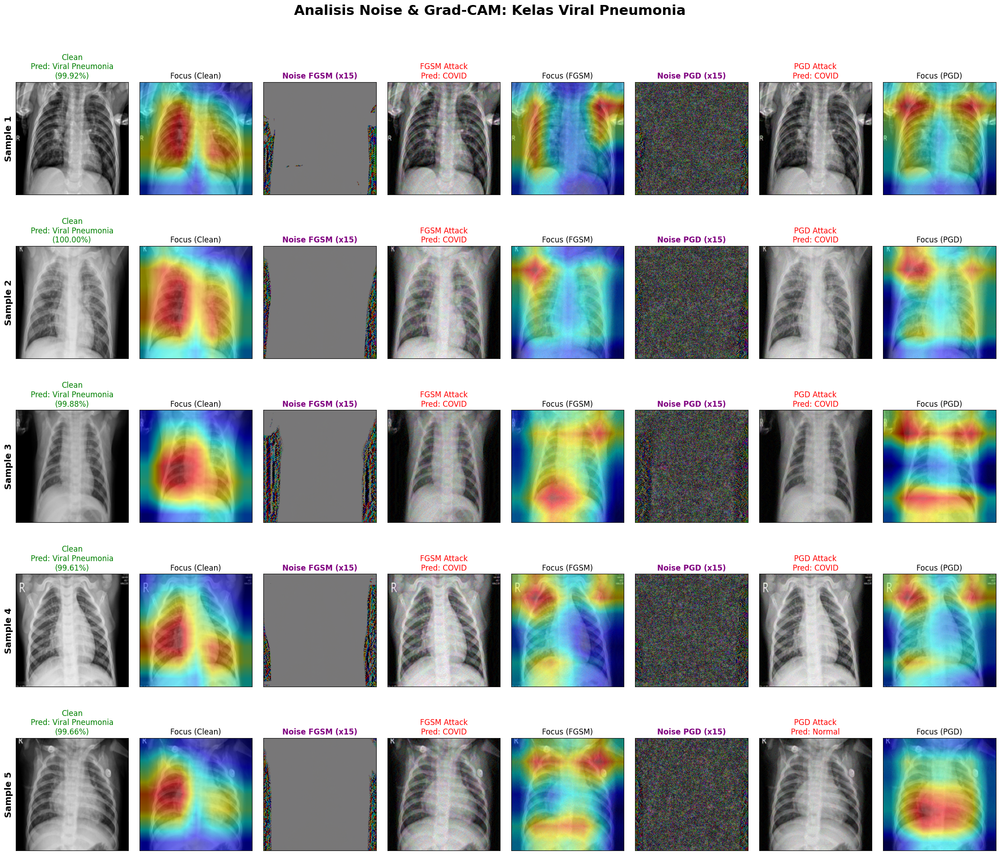

In [16]:
# --- BAGIAN 9: VISUALISASI GRAD-CAM + BENTUK NOISE (8 KOLOM) ---

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# --- 1. Helper: Hitung Visualisasi Noise ---
def compute_noise_diff(clean_img_numpy, adv_img_numpy, amplification=15):
    """
    Menghitung selisih absolute antara gambar clean dan adversarial.
    Amplification digunakan agar noise yang kecil terlihat oleh mata manusia.
    """
    # Hitung selisih absolut (R, G, B)
    diff = np.abs(adv_img_numpy - clean_img_numpy)
    
    # Kalikan agar terlihat (karena epsilon 0.1/255 itu sangat gelap/kecil)
    diff = diff * amplification
    
    # Clip agar tetap di range [0, 1]
    return np.clip(diff, 0, 1)

# --- 2. Fungsi Visualisasi Blok Kelas (Update 8 Kolom) ---
def visualize_class_block_with_noise(model, class_name, class_idx, samples):
    model.eval()
    
    # Target Layer
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_samples = len(samples)
    
    # Setup Plot: N Baris x 8 Kolom (Lebar canvas diperbesar jadi 28)
    fig, axs = plt.subplots(num_samples, 8, figsize=(28, 4.5 * num_samples))
    plt.suptitle(f"Analisis Noise & Grad-CAM: Kelas {class_name}", fontsize=22, fontweight='bold', y=0.95)
    plt.subplots_adjust(wspace=0.1, hspace=0.3)
    
    for i, img_tensor in enumerate(samples):
        img_tensor = img_tensor.unsqueeze(0).to(DEVICE)
        
        # --- A. CLEAN PASS ---
        out_clean = model(img_tensor)
        pred_clean_idx = out_clean.argmax(dim=1).item()
        prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
        cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
        
        # --- B. FGSM ATTACK ---
        adv_fgsm = fgsm_attack(model, img_tensor, torch.tensor([class_idx]), epsilon=8/255)
        out_fgsm = model(adv_fgsm)
        pred_fgsm_idx = out_fgsm.argmax(dim=1).item()
        prob_fgsm = F.softmax(out_fgsm, dim=1)[0][pred_fgsm_idx].item()
        cam_fgsm = cam(input_tensor=adv_fgsm, targets=None)[0]
        
        # --- C. PGD ATTACK ---
        adv_pgd = pgd_attack(model, img_tensor, torch.tensor([class_idx]), eps=8/255, alpha=2/255, steps=10)
        out_pgd = model(adv_pgd)
        pred_pgd_idx = out_pgd.argmax(dim=1).item()
        prob_pgd = F.softmax(out_pgd, dim=1)[0][pred_pgd_idx].item()
        cam_pgd = cam(input_tensor=adv_pgd, targets=None)[0]
        
        # --- D. PERSIAPAN VISUAL (Denormalize) ---
        rgb_clean = denormalize_image(img_tensor[0])
        rgb_fgsm = denormalize_image(adv_fgsm[0])
        rgb_pgd = denormalize_image(adv_pgd[0])
        
        # --- E. HITUNG NOISE (DENGAN AMPLIFIKASI) ---
        noise_fgsm = compute_noise_diff(rgb_clean, rgb_fgsm, amplification=15)
        noise_pgd = compute_noise_diff(rgb_clean, rgb_pgd, amplification=15)
        
        # --- F. GRAD-CAM OVERLAY ---
        viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
        viz_fgsm = show_cam_on_image(rgb_fgsm, cam_fgsm, use_rgb=True)
        viz_pgd = show_cam_on_image(rgb_pgd, cam_pgd, use_rgb=True)
        
        # --- G. PLOTTING (8 KOLOM) ---
        
        # Kolom 1: Clean Image
        axs[i, 0].imshow(rgb_clean)
        axs[i, 0].set_ylabel(f"Sample {i+1}", fontsize=14, fontweight='bold')
        axs[i, 0].set_title(f"Clean\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.2%})", color='green' if pred_clean_idx==class_idx else 'red')
        
        # Kolom 2: Clean CAM
        axs[i, 1].imshow(viz_clean)
        axs[i, 1].set_title("Focus (Clean)")
        
        # Kolom 3: NOISE FGSM (Amplified)
        axs[i, 2].imshow(noise_fgsm)
        axs[i, 2].set_title("Noise FGSM (x15)", fontweight='bold', color='purple')
        
        # Kolom 4: FGSM Image + Result
        axs[i, 3].imshow(rgb_fgsm)
        axs[i, 3].set_title(f"FGSM Attack\nPred: {CLASSES[pred_fgsm_idx]}", color='green' if pred_fgsm_idx==class_idx else 'red')
        
        # Kolom 5: FGSM CAM
        axs[i, 4].imshow(viz_fgsm)
        axs[i, 4].set_title("Focus (FGSM)")
        
        # Kolom 6: NOISE PGD (Amplified)
        axs[i, 5].imshow(noise_pgd)
        axs[i, 5].set_title("Noise PGD (x15)", fontweight='bold', color='purple')
        
        # Kolom 7: PGD Image + Result
        axs[i, 6].imshow(rgb_pgd)
        axs[i, 6].set_title(f"PGD Attack\nPred: {CLASSES[pred_pgd_idx]}", color='green' if pred_pgd_idx==class_idx else 'red')
        
        # Kolom 8: PGD CAM
        axs[i, 7].imshow(viz_pgd)
        axs[i, 7].set_title("Focus (PGD)")
        
        # Matikan axis
        for j in range(8):
            axs[i, j].set_xticks([])
            axs[i, j].set_yticks([])
            if j != 0: axs[i, j].set_ylabel("")

    plt.show()

# --- 3. EKSEKUSI LOOP ---
print("Memulai Visualisasi Lengkap dengan Bentuk Noise...")

# Menggunakan loop yang sama seperti sebelumnya (5 sampel per kelas)
# Pastikan 'get_samples_for_specific_class' dari kode sebelumnya sudah didefinisikan
for idx, class_name in enumerate(CLASSES):
    print(f"\nProcessing Class: {class_name}...")
    samples = get_samples_for_specific_class(dataloaders['test'], idx, num_samples=5)
    
    if len(samples) > 0:
        visualize_class_block_with_noise(model_ft, class_name, idx, samples)
    else:
        print(f"Skipping {class_name} (No samples found).")

# BAGIAN 9a: EKSPERIMEN SENSITIVITAS FGSM (EPSILON KECIL)

Memulai Eksperimen FGSM Sub-Pixel Sensitivity...
Range: 0.1/255 s.d 0.9/255


-> FGSM Eps 0.1/255 | Akurasi: 59.28%


-> FGSM Eps 0.2/255 | Akurasi: 32.88%


-> FGSM Eps 0.3/255 | Akurasi: 21.73%


-> FGSM Eps 0.4/255 | Akurasi: 15.16%


-> FGSM Eps 0.5/255 | Akurasi: 12.14%


-> FGSM Eps 0.6/255 | Akurasi: 10.39%


-> FGSM Eps 0.7/255 | Akurasi: 9.31%


-> FGSM Eps 0.8/255 | Akurasi: 9.26%


-> FGSM Eps 0.9/255 | Akurasi: 9.02%

=== HASIL EKSPERIMEN SUB-PIXEL (FGSM) ===
     Label  Epsilon_Val   Accuracy
0  0.1/255     0.000392  59.282003
1  0.2/255     0.000784  32.876712
2  0.3/255     0.001176  21.728862
3  0.4/255     0.001569  15.162966
4  0.5/255     0.001961  12.139821
5  0.6/255     0.002353  10.392064
6  0.7/255     0.002745   9.305621
7  0.8/255     0.003137   9.258385
8  0.9/255     0.003529   9.022201


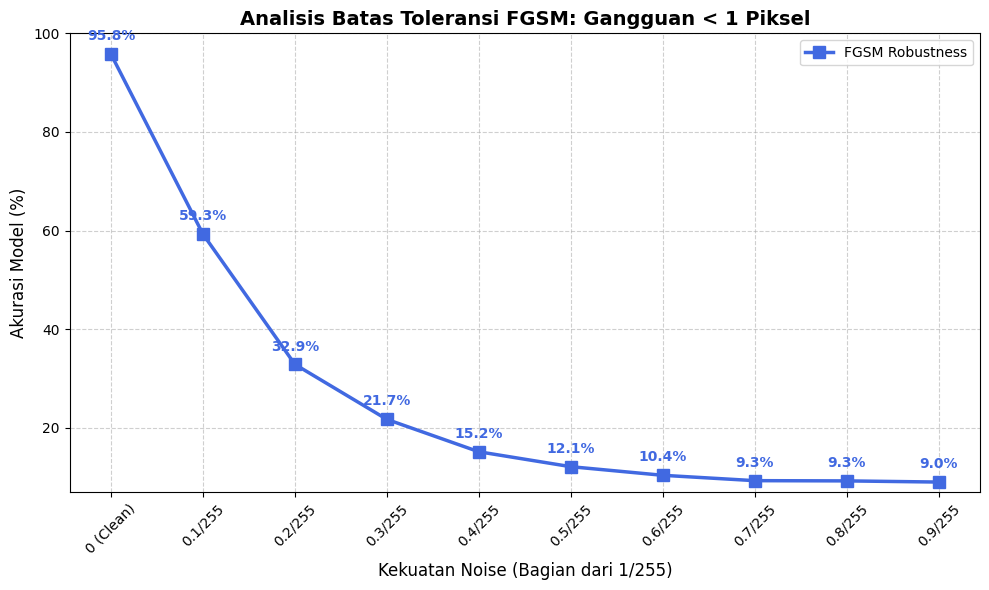

In [17]:
# %% [markdown]
# # BAGIAN 13: EKSPERIMEN FGSM SUB-PIXEL (0.1 - 0.9 per 255) & GRAFIK TOLERANSI

# %%
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- 1. SETUP & DEFINISI FUNGSI FGSM LOKAL ---
# Kita definisikan ulang agar cell ini mandiri
def fgsm_attack_micro(model, images, labels, eps):
    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    images.requires_grad = True
    
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    model.zero_grad()
    loss.backward()
    
    # Normalisasi perturbasi berdasarkan std dataset
    # (Karena input model sudah dinormalisasi)
    std_tensor = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    eps_norm = eps / std_tensor
    
    # FGSM Formula: x + eps * sign(grad)
    data_grad = images.grad.data
    perturbed_image = images + eps_norm * data_grad.sign()
    
    return perturbed_image

# --- 2. CONFIG LOOP MIKRO ---
micro_vals = [i/10 for i in range(1, 10)] # [0.1, 0.2, ... 0.9]
epsilons_micro = [m/255 for m in micro_vals] 
results_fgsm_micro = []

print(f"Memulai Eksperimen FGSM Sub-Pixel Sensitivity...")
print(f"Range: 0.1/255 s.d 0.9/255")

# --- 3. EKSEKUSI LOOP ---
model_ft.eval()

# Menggunakan 'test_loader' atau 'dataloaders['test']'
target_loader = test_loader if 'test_loader' in locals() else dataloaders['test']

for i, eps in enumerate(epsilons_micro):
    val_label = micro_vals[i]
    
    correct = 0
    total = 0
    
    # Loop Evaluasi
    for inputs, labels in tqdm(target_loader, desc=f"FGSM Eps {val_label:.1f}/255", leave=False):
        # Generate FGSM Attack
        adv_inputs = fgsm_attack_micro(model_ft, inputs, labels, eps=eps)
        
        with torch.no_grad():
            outputs = model_ft(adv_inputs)
            _, preds = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (preds == labels.to(DEVICE)).sum().item()

    # Simpan Hasil
    acc = 100 * correct / total
    results_fgsm_micro.append({
        'Label': f"{val_label:.1f}/255",
        'Epsilon_Val': eps,
        'Accuracy': acc
    })
    
    print(f"-> FGSM Eps {val_label:.1f}/255 | Akurasi: {acc:.2f}%")

# --- 4. DATA FRAME & GRAFIK ---
df_fgsm_micro = pd.DataFrame(results_fgsm_micro)
print("\n=== HASIL EKSPERIMEN SUB-PIXEL (FGSM) ===")
print(df_fgsm_micro)

# Plotting
plt.figure(figsize=(10, 6))
plot_x_labels = ["0 (Clean)"] + df_fgsm_micro['Label'].tolist()
# Ambil baseline clean accuracy (asumsi sekitar 95.75% atau ambil dari history clean)
baseline_acc = 95.75 
plot_y_vals = [baseline_acc] + df_fgsm_micro['Accuracy'].tolist() 
x_indices = range(len(plot_x_labels))

plt.plot(x_indices, plot_y_vals, marker='s', color='royalblue', linewidth=2.5, markersize=8, label='FGSM Robustness')
plt.title("Analisis Batas Toleransi FGSM: Gangguan < 1 Piksel", fontsize=14, fontweight='bold')
plt.xlabel("Kekuatan Noise (Bagian dari 1/255)", fontsize=12)
plt.ylabel("Akurasi Model (%)", fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.xticks(x_indices, plot_x_labels, rotation=45)
plt.ylim(min(plot_y_vals)-2, 100) # Auto adjust limit bawah
plt.legend()

# Anotasi Angka
for i, v in enumerate(plot_y_vals):
    plt.annotate(f"{v:.1f}%", (x_indices[i], plot_y_vals[i]), 
                 textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold', color='royalblue')

plt.tight_layout()
plt.show()

Memulai Visualisasi Mikro-FGSM (0.1/255 - 0.9/255)...
Generating FGSM Micro-Progression for COVID... Done.


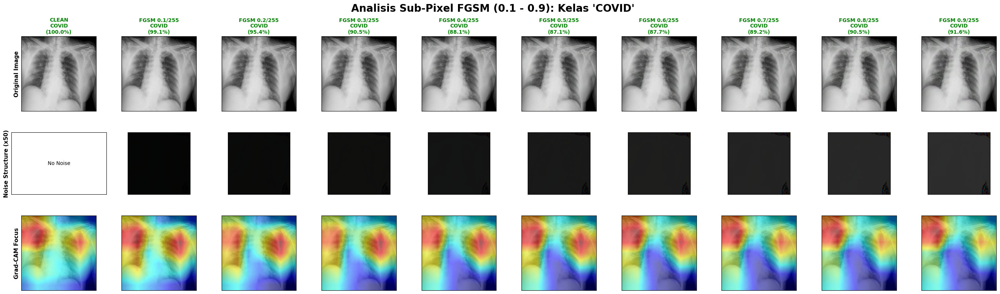

Generating FGSM Micro-Progression for Lung_Opacity... Done.


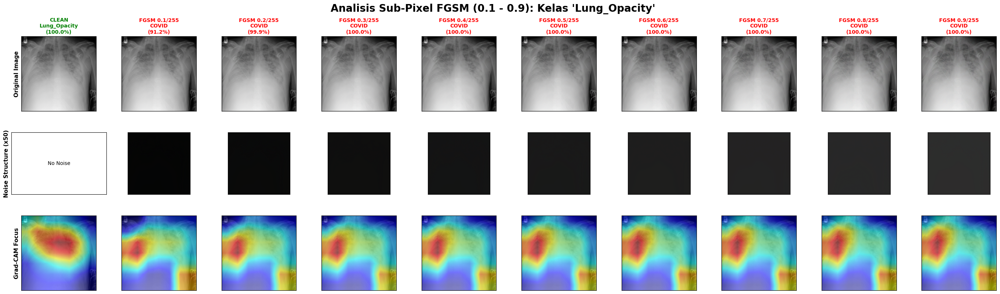

Generating FGSM Micro-Progression for Normal... Done.


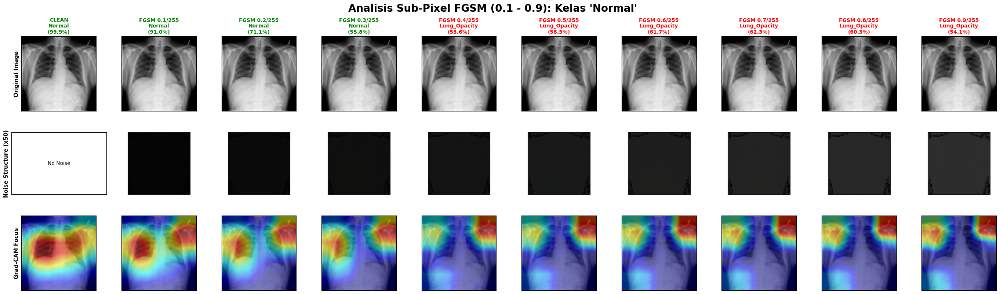

Generating FGSM Micro-Progression for Viral Pneumonia... Done.


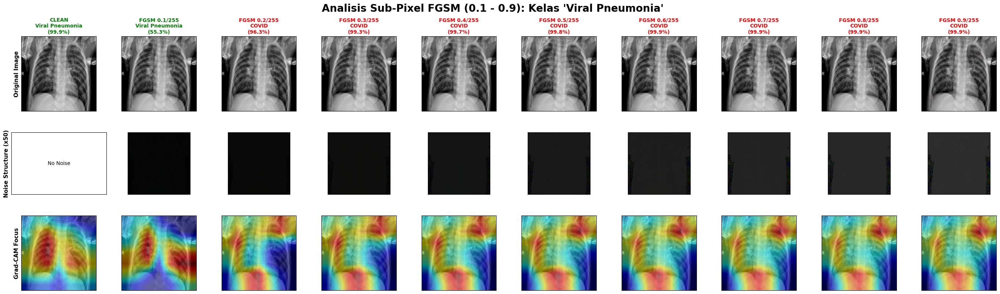

In [18]:
# %% [markdown]
# # BAGIAN 14: VISUALISASI LENGKAP FGSM MICRO-PROGRESSION (Clean s.d 0.9/255)

# %%
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- 1. SETUP VAR ---
micro_vals = [i/10 for i in range(1, 10)]
epsilons_progression_fgsm = [m/255 for m in micro_vals]
epsilon_labels_fgsm = [f"{m:.1f}/255" for m in micro_vals]

# --- 2. HELPER FUNCTIONS ---
def denormalize_img(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_amp(clean, adv, amp=50): 
    # Amplifikasi noise agar terlihat mata (karena sub-pixel sangat gelap)
    diff = np.abs(adv - clean) * amp
    return np.clip(diff, 0, 1)

# Helper FGSM yang sama dengan cell sebelumnya (local definition)
def fgsm_attack_viz(model, images, labels, eps):
    images = images.clone().detach().to(DEVICE)
    images.requires_grad = True
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels.to(DEVICE))
    model.zero_grad()
    loss.backward()
    std_tensor = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    return images + (eps / std_tensor) * images.grad.data.sign()

# --- 3. FUNGSI VISUALISASI UTAMA FGSM ---
def visualize_fgsm_progression_micro(model, img_tensor, label_idx, class_name):
    model.eval()
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression_fgsm) + 1 # 10 Kolom
    
    # Setup Grid Plot
    fig = plt.figure(figsize=(35, 9))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.05)
    
    fig.suptitle(f"Analisis Sub-Pixel FGSM (0.1 - 0.9): Kelas '{class_name}'", fontsize=20, fontweight='bold', y=0.98)

    # --- A. KOLOM CLEAN (BASELINE) ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_img(img_tensor[0])
    
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # Plot Clean
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    title_color = 'green' if pred_clean_idx == label_idx else 'red'
    ax0.set_title(f"CLEAN\n{CLASSES[pred_clean_idx]}\n({prob_clean:.1%})", color=title_color, fontweight='bold', fontsize=10)
    ax0.set_ylabel("Original Image", fontsize=11, fontweight='bold')
    
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "No Noise", ha='center', va='center')
    ax1.set_ylabel("Noise Structure (x50)", fontsize=11, fontweight='bold')
    
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_ylabel("Grad-CAM Focus", fontsize=11, fontweight='bold')

    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- B. LOOP PROGRESI EPSILON FGSM ---
    print(f"Generating FGSM Micro-Progression for {class_name}...", end=" ")
    
    for j, eps in enumerate(epsilons_progression_fgsm):
        col_idx = j + 1
        
        # 1. Attack (FGSM)
        adv_tensor = fgsm_attack_viz(model, img_tensor, torch.tensor([label_idx]), eps=eps)
        
        # 2. Predict
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # 3. CAM
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # 4. Viz Prep
        rgb_adv = denormalize_img(adv_tensor[0])
        noise_amp = compute_noise_amp(rgb_clean, rgb_adv, amp=50) # Amplified 50x
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # 5. Plotting
        # Baris 1: Result Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"FGSM {epsilon_labels_fgsm[j]}\n{CLASSES[pred_adv_idx]}\n({prob_adv:.1%})", color=color, fontweight='bold', fontsize=10)
        
        # Baris 2: Noise
        ax_noise = plt.subplot(gs[1, col_idx])
        ax_noise.imshow(noise_amp)
        
        # Baris 3: CAM
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- 4. EKSEKUSI LOOP VISUALISASI ---
print("Memulai Visualisasi Mikro-FGSM (0.1/255 - 0.9/255)...")

# Menggunakan sampel representatif yang mungkin sudah didapat sebelumnya
# Jika belum ada variabel 'representative_samples_v2', kita ambil ulang
if 'representative_samples_v2' not in locals() or len(representative_samples_v2) == 0:
    # Fungsi pencari sampel sederhana (Safe Mode)
    def get_samples_safe(loader, cls_list):
        samps = {}
        for inputs, lbls in loader:
            for i in range(len(lbls)):
                l = lbls[i].item()
                if l not in samps: samps[l] = inputs[i]
            if len(samps) == len(cls_list): break
        return [samps[i] for i in range(len(cls_list)) if i in samps]
    
    target_loader = test_loader if 'test_loader' in locals() else dataloaders['test']
    representative_samples_v2 = get_samples_safe(target_loader, CLASSES)

# Loop Per Kelas
if len(representative_samples_v2) > 0:
    for i, sample_tensor in enumerate(representative_samples_v2):
        label_idx = i 
        class_name = CLASSES[label_idx]
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_fgsm_progression_micro(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Error: Tidak ada sampel gambar yang ditemukan.")

In [19]:
# --- BAGIAN 10 (VERSI FGSM): VISUALISASI PROGRESI FGSM (Epsilon 0.01 - 0.1) ---

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- KONFIGURASI EPSILON (SAMA DENGAN PGD) ---
epsilons_progression = [0.01, 0.025, 0.05, 0.1]
epsilon_labels = ["0.01 (Low)", "0.025 (Med-Low)", "0.05 (Med-High)", "0.1 (High)"]

# --- HELPER FUNCTIONS ---
def denormalize_image(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_diff_amp(clean_img_np, adv_img_np, amp=1):
    # Hitung selisih absolut dan amplifikasi agar terlihat mata
    diff = np.abs(adv_img_np - clean_img_np) * amp
    return np.clip(diff, 0, 1)

# --- FUNGSI VISUALISASI INTI (FGSM) ---
def visualize_fgsm_progression_block(model, img_tensor, label_idx, class_name):
    model.eval()
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression) + 1 # +1 untuk kolom Clean
    
    # Setup Grid Plot: 3 Baris x N Kolom
    fig = plt.figure(figsize=(4 * num_cols, 10))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.1)
    
    fig.suptitle(f"Analisis Progresi FGSM: Kelas Asli '{class_name}'", fontsize=20, fontweight='bold', y=0.98)

    # --- 1. PROSES DATA CLEAN (KOLOM PERTAMA) ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_image(img_tensor[0])
    
    # Prediksi Clean
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    # CAM Clean
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # Plot Kolom Clean (Index 0)
    # Baris 1: Image
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    ax0.set_title(f"CLEAN (Asli)\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.2%})", color='green' if pred_clean_idx==label_idx else 'red', fontweight='bold')
    ax0.set_ylabel("Gambar + Prediksi", fontsize=12, fontweight='bold')
    
    # Baris 2: Noise (Kosong untuk clean)
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "Tidak Ada Noise", ha='center', va='center')
    ax1.set_ylabel("Visual Noise (x20)", fontsize=12, fontweight='bold')
    
    # Baris 3: CAM
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_title("Fokus Model (Grad-CAM)")
    ax2.set_ylabel("Grad-CAM Heatmap", fontsize=12, fontweight='bold')

    # Matikan ticks kolom 0
    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- 2. LOOP PROGRESI EPSILON (KOLOM 2 dst) ---
    print(f"Generating FGSM progression for {class_name}...", end=" ")
    for j, eps in enumerate(epsilons_progression):
        col_idx = j + 1
        print(f"{epsilon_labels[j]}...", end=" ")
        
        # A. Generate FGSM Attack (Menggunakan fungsi fgsm_attack yang sudah didefinisikan sebelumnya)
        adv_tensor = fgsm_attack(model, img_tensor, torch.tensor([label_idx]), epsilon=eps)
        
        # B. Prediksi pada Gambar Adv
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # C. Generate CAM pada Gambar Adv
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # D. Proses Visualisasi
        rgb_adv = denormalize_image(adv_tensor[0])
        # Hitung Noise (Amplified x20 agar terlihat, karena epsilon kecil)
        noise_amp = compute_noise_diff_amp(rgb_clean, rgb_adv, amp=20)
        # Overlay CAM
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # E. PLOTTING
        # Baris 1: Adv Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"EPS: {epsilon_labels[j]}\nPred: {CLASSES[pred_adv_idx]}\n({prob_adv:.2%})", color=color, fontweight='bold')
        
        # Baris 2: Noise Only
        ax_noise = plt.subplot(gs[1, col_idx])
        ax_noise.imshow(noise_amp)
        # Menampilkan epsilon sebagai integer untuk judul (opsional, disesuaikan agar rapi)
        ax_noise.set_title(f"Struktur Noise\n(Eps {eps})")
        
        # Baris 3: CAM Overlay
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        ax_cam.set_title(f"Pergeseran Fokus\n(Eps {eps})")
        
        # Matikan axis
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- EKSEKUSI UTAMA ---
# Pastikan representative_samples sudah ada dari kode sebelumnya
# Jika belum, uncomment baris di bawah ini:
# representative_samples = get_one_sample_per_class(dataloaders['test'], CLASSES)

if 'representative_samples' in locals() and len(representative_samples) > 0:
    for i, sample_tensor in enumerate(representative_samples):
        label_idx = i
        class_name = CLASSES[label_idx]
        
        # Tambahkan dimensi batch
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_fgsm_progression_block(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Tidak ada sampel yang ditemukan. Harap jalankan bagian pencarian sampel (get_one_sample_per_class) terlebih dahulu.")

Tidak ada sampel yang ditemukan. Harap jalankan bagian pencarian sampel (get_one_sample_per_class) terlebih dahulu.


Mencari sampel representatif untuk setiap kelas...
Generating FGSM progression for COVID... Done.


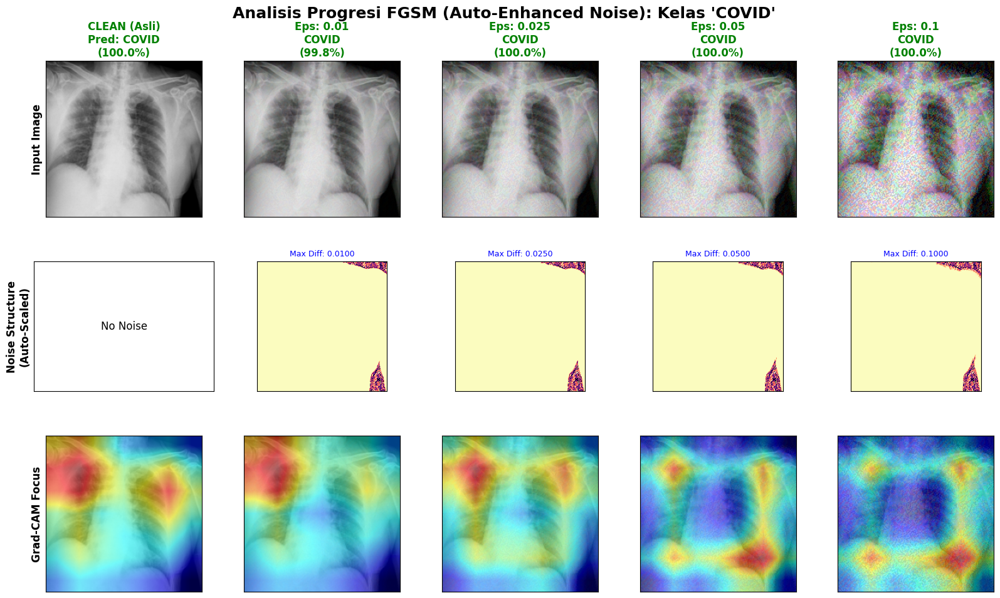

Generating FGSM progression for Lung_Opacity... Done.


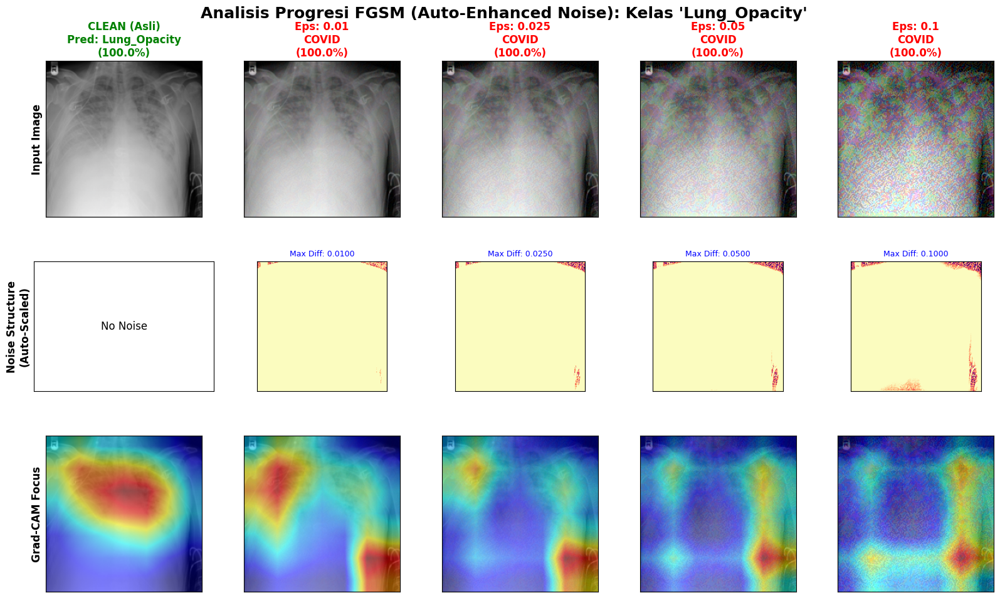

Generating FGSM progression for Normal... Done.


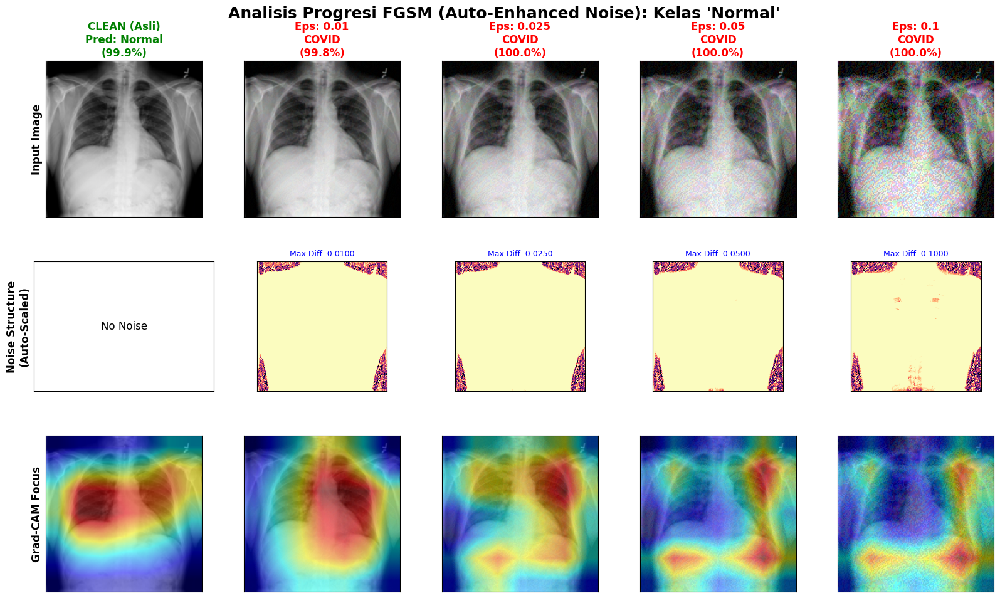

Generating FGSM progression for Viral Pneumonia... Done.


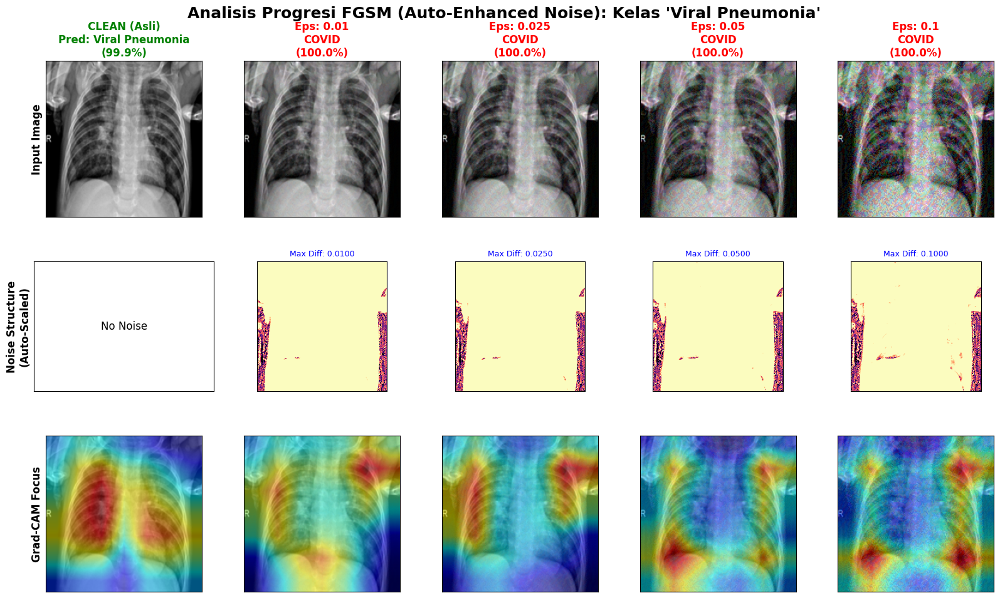

In [20]:
# %% [markdown]
# # BAGIAN 10 (VERSI FGSM REVISI): VISUALISASI PROGRESI FGSM (Epsilon 0.01 - 0.1)
# # Menggunakan Auto-Contrast Heatmap untuk memperjelas noise struktur FGSM

# %%
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- 1. KONFIGURASI EPSILON (SAMA DENGAN PGD) ---
epsilons_progression = [0.01, 0.025, 0.05, 0.1]
epsilon_labels = [f"{e}" for e in epsilons_progression]

# --- 2. HELPER FUNCTIONS (Sama dengan PGD) ---

def denormalize_image(tensor):
    """Mengubah tensor kembali ke gambar RGB standar [0,1]"""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_enhanced(clean_img_np, adv_img_np):
    """
    Menghitung noise dengan Auto-Scaling (Min-Max Normalization).
    Output: Heatmap 2D (H, W) dengan cmap Magma nanti.
    """
    # 1. Hitung selisih absolut
    diff = np.abs(adv_img_np - clean_img_np)
    
    # 2. Rata-ratakan channel RGB -> Intensitas
    diff_heatmap = np.mean(diff, axis=2)
    
    # 3. Auto-Scaling: Paksa nilai max jadi 1.0
    max_val = diff_heatmap.max()
    if max_val > 0:
        diff_heatmap = diff_heatmap / max_val
        
    return diff_heatmap, max_val

# --- 3. FUNGSI VISUALISASI INTI (FGSM) ---

def visualize_fgsm_progression_enhanced(model, img_tensor, label_idx, class_name):
    model.eval()
    
    # Target Layer
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression) + 1 # +1 untuk Clean
    
    # Setup Grid Plot
    fig = plt.figure(figsize=(4 * num_cols, 11))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.1)
    
    fig.suptitle(f"Analisis Progresi FGSM (Auto-Enhanced Noise): Kelas '{class_name}'", fontsize=18, fontweight='bold', y=0.96)

    # --- A. PROSES DATA CLEAN (KOLOM 1) ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_image(img_tensor[0])
    
    # Prediksi
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    # CAM
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # PLOT CLEAN
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    title_col = 'green' if pred_clean_idx == label_idx else 'red'
    ax0.set_title(f"CLEAN (Asli)\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.1%})", color=title_col, fontweight='bold')
    ax0.set_ylabel("Input Image", fontsize=12, fontweight='bold')
    
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "No Noise", ha='center', va='center', fontsize=12)
    ax1.set_ylabel("Noise Structure\n(Auto-Scaled)", fontsize=12, fontweight='bold')
    
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_ylabel("Grad-CAM Focus", fontsize=12, fontweight='bold')

    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- B. LOOP PROGRESI EPSILON (KOLOM 2 dst) ---
    print(f"Generating FGSM progression for {class_name}...", end=" ")
    
    for j, eps in enumerate(epsilons_progression):
        col_idx = j + 1
        
        # 1. GENERATE ATTACK (FGSM)
        # Menggunakan fungsi fgsm_attack yang sudah ada di Bagian 3 / global scope
        adv_tensor = fgsm_attack(model, img_tensor, torch.tensor([label_idx]), epsilon=eps)
        
        # 2. PREDIKSI
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # 3. CAM
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # 4. PREPARE VISUALS
        rgb_adv = denormalize_image(adv_tensor[0])
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # --- TEKNIK PERJELAS NOISE ---
        noise_heatmap, max_diff = compute_noise_enhanced(rgb_clean, rgb_adv)
        
        # 5. PLOTTING
        # Baris 1: Adv Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"Eps: {epsilon_labels[j]}\n{CLASSES[pred_adv_idx]}\n({prob_adv:.1%})", color=color, fontweight='bold')
        
        # Baris 2: Noise (HEATMAP MAGMA)
        ax_noise = plt.subplot(gs[1, col_idx])
        im = ax_noise.imshow(noise_heatmap, cmap='magma', vmin=0, vmax=1)
        ax_noise.set_title(f"Max Diff: {max_diff:.4f}", fontsize=9, color='blue')
        
        # Baris 3: CAM
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- EKSEKUSI UTAMA ---

# Ambil sampel (menggunakan fungsi safe dari sebelumnya)
try:
    if 'get_one_sample_per_class_safe' in locals():
        target_loader = test_loader if 'test_loader' in locals() else dataloaders['test']
        representative_samples = get_one_sample_per_class_safe(target_loader, CLASSES)
    else:
        representative_samples = get_one_sample_per_class(dataloaders['test'], CLASSES)
except NameError:
    print("Helper function pencari sampel tidak ditemukan. Pastikan cell sebelumnya dijalankan.")
    representative_samples = []

# Loop visualisasi per kelas
if len(representative_samples) > 0:
    for i, sample_tensor in enumerate(representative_samples):
        label_idx = i
        class_name = CLASSES[label_idx]
        
        # Tambahkan dimensi batch
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_fgsm_progression_enhanced(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Tidak ada sampel untuk divisualisasikan.")

# BAGIAN 9b: EKSPERIMEN SENSITIVITAS PGD (EPSILON KECIL)

Memulai Eksperimen PGD Custom Sensitivity...
Target Epsilon (per 255): [0.01, 0.025, 0.05, 0.1, 0.3]


-> PGD Eps 0.01/255 | Akurasi: 92.82% | ASR: 7.18%


-> PGD Eps 0.025/255 | Akurasi: 86.30% | ASR: 13.70%


-> PGD Eps 0.05/255 | Akurasi: 66.65% | ASR: 33.35%


-> PGD Eps 0.1/255 | Akurasi: 25.51% | ASR: 74.49%


-> PGD Eps 0.3/255 | Akurasi: 0.05% | ASR: 99.95%

=== HASIL SENSITIVITAS PGD (CUSTOM) ===
  Epsilon Label  Epsilon Val  Accuracy (%)    ASR (%)
0      0.01/255     0.000039     92.820028   7.179972
1     0.025/255     0.000098     86.301370  13.698630
2      0.05/255     0.000196     66.650921  33.349079
3       0.1/255     0.000392     25.507794  74.492206
4       0.3/255     0.001176      0.047237  99.952763


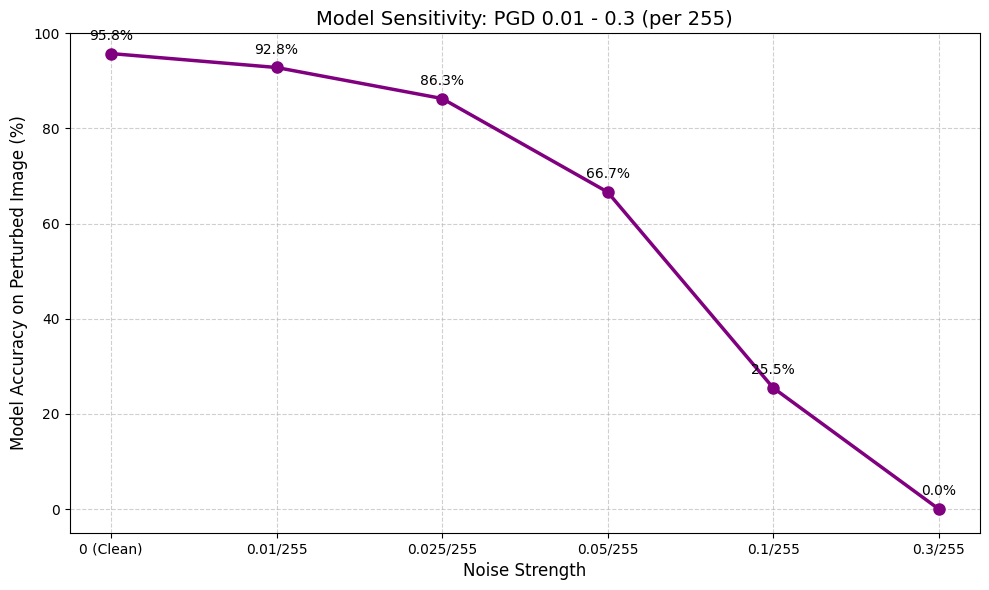

In [21]:
# %% [markdown]
# # BAGIAN 9b (REVISI): EKSPERIMEN SENSITIVITAS PGD CUSTOM (0.1 - 1.0)

# %%
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tqdm import tqdm

# --- 1. CONFIG BARU ---
# Target values yang diminta: 0.01, 0.025, 0.05, 0.1, 0.3
custom_vals = [0.01, 0.025, 0.05, 0.1, 0.3]
epsilons_custom = [v/255 for v in custom_vals]

# Variable penampung hasil baru (menggantikan yang lama)
results_sensitivity_custom = []

print(f"Memulai Eksperimen PGD Custom Sensitivity...")
print(f"Target Epsilon (per 255): {custom_vals}")

# Pastikan model di mode eval
model_ft.eval()

# Menggunakan test_loader jika ada, atau fallback ke dataloaders['test']
target_loader = test_loader if 'test_loader' in locals() else dataloaders['test']

# --- 2. LOOP EKSPERIMEN ---
for i, eps in enumerate(epsilons_custom):
    val_label = custom_vals[i]
    
    # Alpha diset seperempat dari epsilon agar langkahnya proporsional
    # Untuk epsilon sangat kecil, alpha juga sangat kecil
    current_alpha = eps / 4 
    
    correct = 0
    total = 0
    
    # Loop Evaluasi
    desc_text = f"PGD Eps {val_label}/255"
    for inputs, labels in tqdm(target_loader, desc=desc_text, leave=False):
        # Generate PGD Attack
        # Pastikan fungsi pgd_attack sudah didefinisikan di cell sebelumnya
        adv_inputs = pgd_attack(model_ft, inputs, labels, 
                                eps=eps, 
                                alpha=current_alpha, 
                                steps=10) # 10 steps standar
        
        with torch.no_grad():
            outputs = model_ft(adv_inputs)
            _, preds = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (preds == labels.to(DEVICE)).sum().item()
            
    # Simpan Hasil
    acc = 100 * correct / total
    asr = 100 - acc
    
    results_sensitivity_custom.append({
        'Epsilon Label': f"{val_label}/255",
        'Epsilon Val': eps,
        'Accuracy (%)': acc,
        'ASR (%)': asr
    })
    
    print(f"-> {desc_text} | Akurasi: {acc:.2f}% | ASR: {asr:.2f}%")

# --- 3. VISUALISASI HASIL CUSTOM ---
df_custom = pd.DataFrame(results_sensitivity_custom)
print("\n=== HASIL SENSITIVITAS PGD (CUSTOM) ===")
print(df_custom)

plt.figure(figsize=(10, 6))
# Tambahkan titik 0 (Clean) untuk grafik
clean_acc_est = 95.75 # Atau ambil dinamically dari metrics_clean_pgd['accuracy'] jika ada
plot_x_labels = ["0 (Clean)"] + df_custom['Epsilon Label'].tolist()
plot_y_vals = [clean_acc_est] + df_custom['Accuracy (%)'].tolist()
x_indices = range(len(plot_x_labels))

plt.plot(x_indices, plot_y_vals, marker='o', color='purple', linewidth=2.5, markersize=8, label='PGD Custom')
plt.title("Model Sensitivity: PGD 0.01 - 0.3 (per 255)", fontsize=14)
plt.xlabel("Noise Strength", fontsize=12)
plt.ylabel("Model Accuracy on Perturbed Image (%)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(x_indices, plot_x_labels)
plt.ylim(min(plot_y_vals)-5, 100)

for i, v in enumerate(plot_y_vals):
    plt.annotate(f"{v:.1f}%", (x_indices[i], plot_y_vals[i]), 
                 textcoords="offset points", xytext=(0,10), ha='center')

plt.tight_layout()
plt.show()

# BAGIAN 10: VISUALISASI PROGRESI PGD (Epsilon 1 sampai 8)

Mencari sampel representatif untuk setiap kelas...
Generating PGD progression for COVID... 0.01/255... 0.025/255... 0.05/255... 0.1/255... Done.


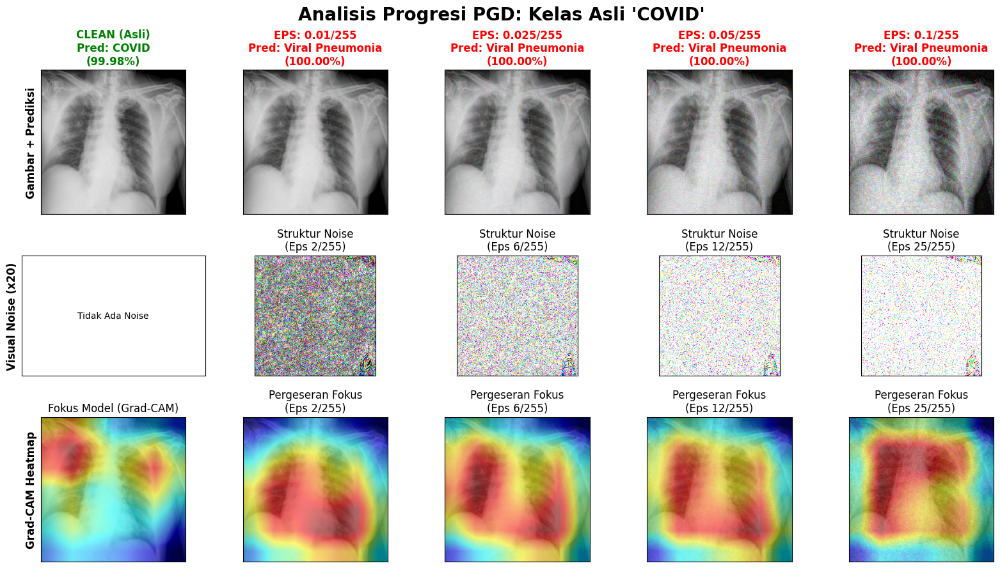

Generating PGD progression for Lung_Opacity... 0.01/255... 0.025/255... 0.05/255... 0.1/255... Done.


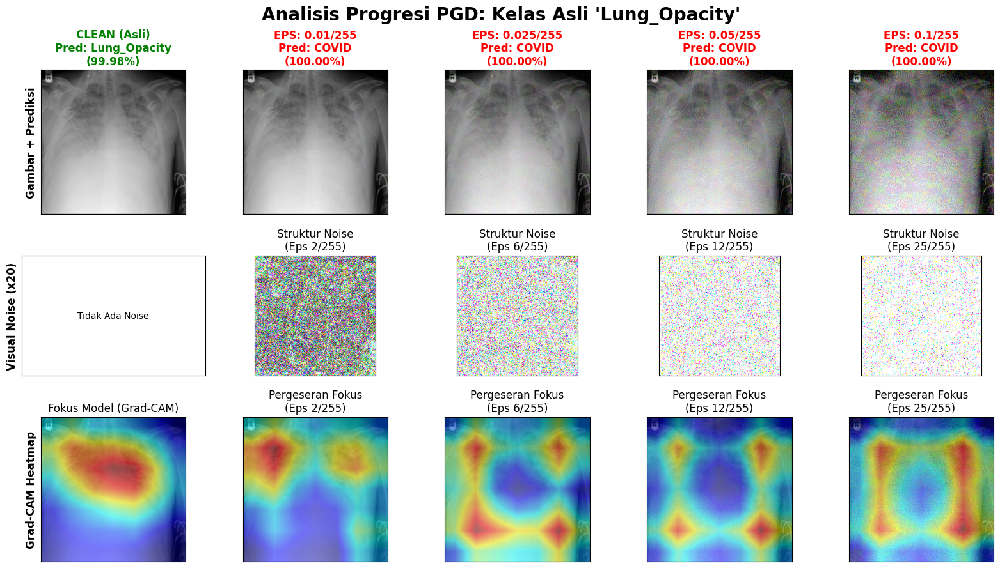

Generating PGD progression for Normal... 0.01/255... 0.025/255... 0.05/255... 0.1/255... Done.


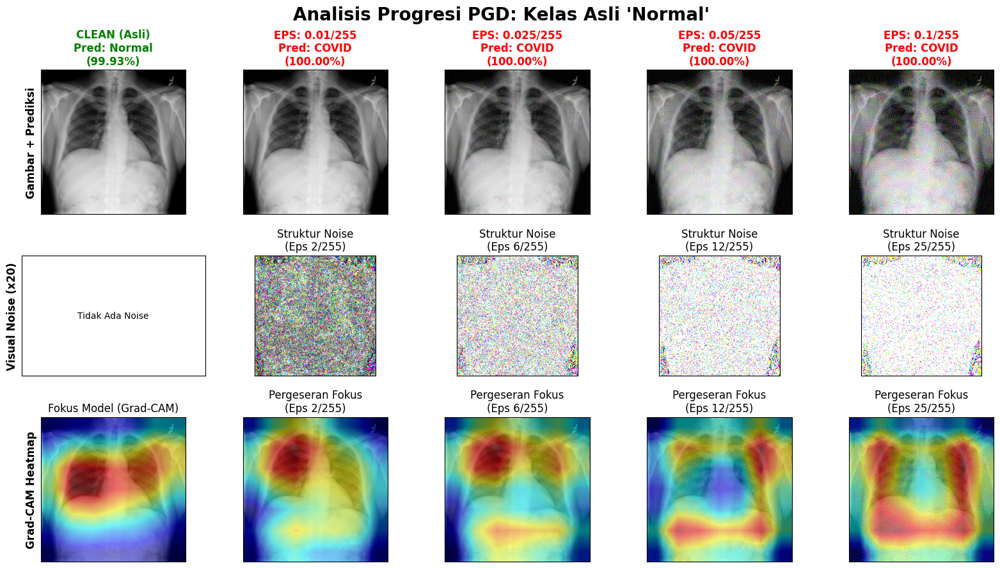

Generating PGD progression for Viral Pneumonia... 0.01/255... 0.025/255... 0.05/255... 0.1/255... Done.


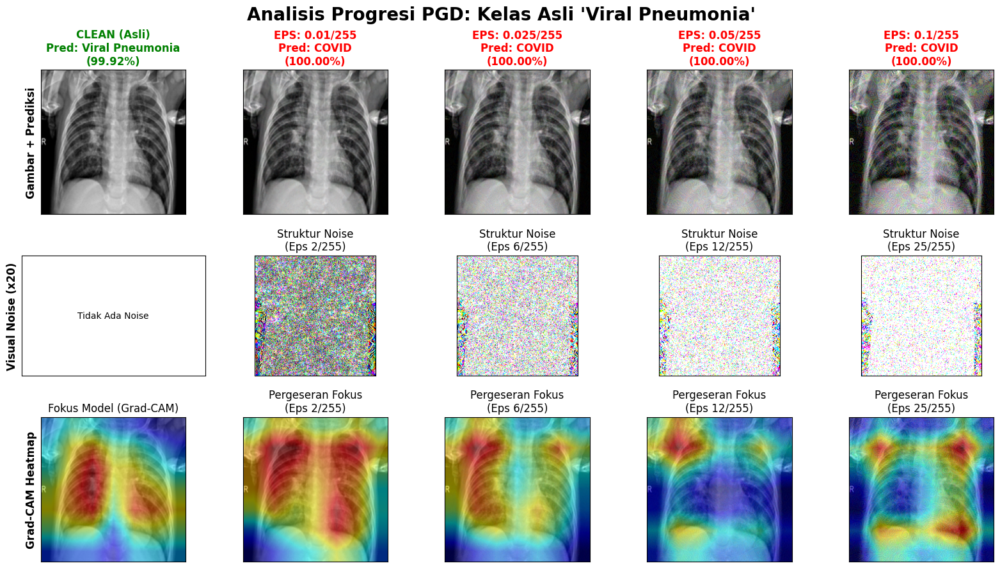

In [22]:
# --- BAGIAN 10: VISUALISASI PROGRESI PGD (Epsilon 1 sampai 8) ---

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- KONFIGURASI EPSILON ---
# Kita akan melihat 4 tingkat keparahan serangan
epsilons_progression = [0.01, 0.025, 0.05, 0.1]
epsilon_labels = ["0.01/255", "0.025/255", "0.05/255", "0.1/255"]

# --- HELPER FUNCTIONS (Pastikan ini ada) ---
def denormalize_image(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_diff_amp(clean_img_np, adv_img_np, amp=1):
    # Hitung selisih absolut dan amplifikasi agar terlihat mata
    diff = np.abs(adv_img_np - clean_img_np) * amp
    return np.clip(diff, 0, 1)

# --- FUNGSI VISUALISASI INTI ---
def visualize_pgd_progression_block(model, img_tensor, label_idx, class_name):
    model.eval()
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression) + 1 # +1 untuk kolom Clean
    
    # Setup Grid Plot: 3 Baris x N Kolom
    fig = plt.figure(figsize=(4 * num_cols, 10))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.1)
    
    fig.suptitle(f"Analisis Progresi PGD: Kelas Asli '{class_name}'", fontsize=20, fontweight='bold', y=0.98)

    # --- 1. PROSES DATA CLEAN (KOLOM PERTAMA) ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_image(img_tensor[0])
    
    # Prediksi Clean
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    # CAM Clean
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # Plot Kolom Clean (Index 0)
    # Baris 1: Image
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    ax0.set_title(f"CLEAN (Asli)\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.2%})", color='green' if pred_clean_idx==label_idx else 'red', fontweight='bold')
    ax0.set_ylabel("Gambar + Prediksi", fontsize=12, fontweight='bold')
    
    # Baris 2: Noise (Kosong untuk clean)
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "Tidak Ada Noise", ha='center', va='center')
    ax1.set_ylabel("Visual Noise (x20)", fontsize=12, fontweight='bold')
    
    # Baris 3: CAM
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_title("Fokus Model (Grad-CAM)")
    ax2.set_ylabel("Grad-CAM Heatmap", fontsize=12, fontweight='bold')

    # Matikan ticks kolom 0
    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- 2. LOOP PROGRESI EPSILON (KOLOM 2 dst) ---
    print(f"Generating PGD progression for {class_name}...", end=" ")
    for j, eps in enumerate(epsilons_progression):
        col_idx = j + 1
        print(f"{epsilon_labels[j]}...", end=" ")
        
        # A. Generate PGD Attack
        # Alpha disesuaikan: eps/4 agar langkahnya proporsional
        adv_tensor = pgd_attack(model, img_tensor, torch.tensor([label_idx]), 
                                eps=eps, alpha=eps/4, steps=10)
        
        # B. Prediksi pada Gambar Adv
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # C. Generate CAM pada Gambar Adv
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # D. Proses Visualisasi
        rgb_adv = denormalize_image(adv_tensor[0])
        # Hitung Noise (Amplified x20)
        noise_amp = compute_noise_diff_amp(rgb_clean, rgb_adv, amp=100)
        # Overlay CAM
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # E. PLOTTING
        # Baris 1: Adv Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"EPS: {epsilon_labels[j]}\nPred: {CLASSES[pred_adv_idx]}\n({prob_adv:.2%})", color=color, fontweight='bold')
        
        # Baris 2: Noise Only
        ax_noise = plt.subplot(gs[1, col_idx])
        ax_noise.imshow(noise_amp)
        ax_noise.set_title(f"Struktur Noise\n(Eps {int(eps*255)}/255)")
        
        # Baris 3: CAM Overlay
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        ax_cam.set_title(f"Pergeseran Fokus\n(Eps {int(eps*255)}/255)")
        
        # Matikan axis
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- EKSEKUSI UTAMA ---
# Ambil 1 sampel representatif per kelas
# (Pastikan fungsi 'get_one_sample_per_class' dari Bagian 6 sudah ada)
try:
    representative_samples = get_one_sample_per_class(dataloaders['test'], CLASSES)
except NameError:
    print("Error: Fungsi 'get_one_sample_per_class' belum didefinisikan. Jalankan kode Bagian 6 terlebih dahulu.")
    representative_samples = []

# Loop visualisasi per kelas
if len(representative_samples) > 0:
    for i, sample_tensor in enumerate(representative_samples):
        label_idx = i # Karena fungsi get_one_sample mengurutkan berdasarkan index kelas
        class_name = CLASSES[label_idx]
        
        # Tambahkan dimensi batch
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_pgd_progression_block(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Tidak ada sampel yang ditemukan untuk visualisasi.")

# update kode diatas dengan epsilon yang benar2 lebih kecil namun tetap memperlihatkan noise yang diberikan tersebut

Mencari sampel representatif untuk setiap kelas...
Generating PGD progression for COVID... Done.


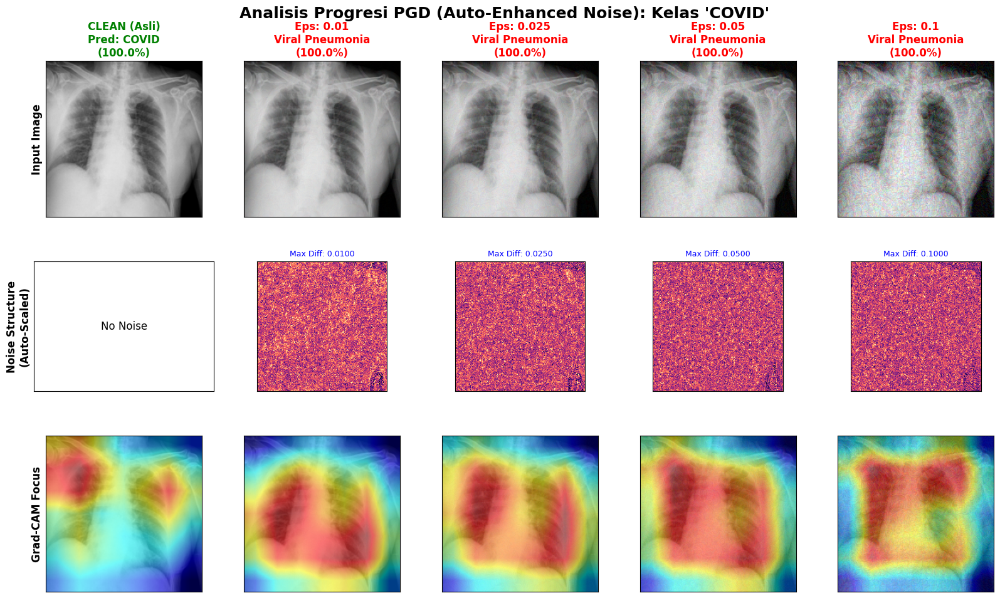

Generating PGD progression for Lung_Opacity... Done.


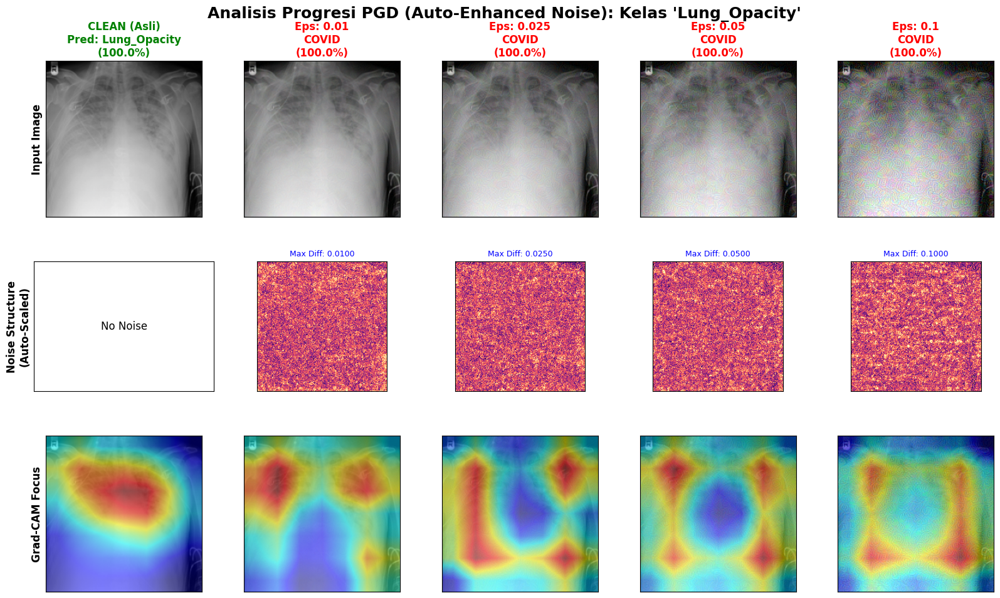

Generating PGD progression for Normal... Done.


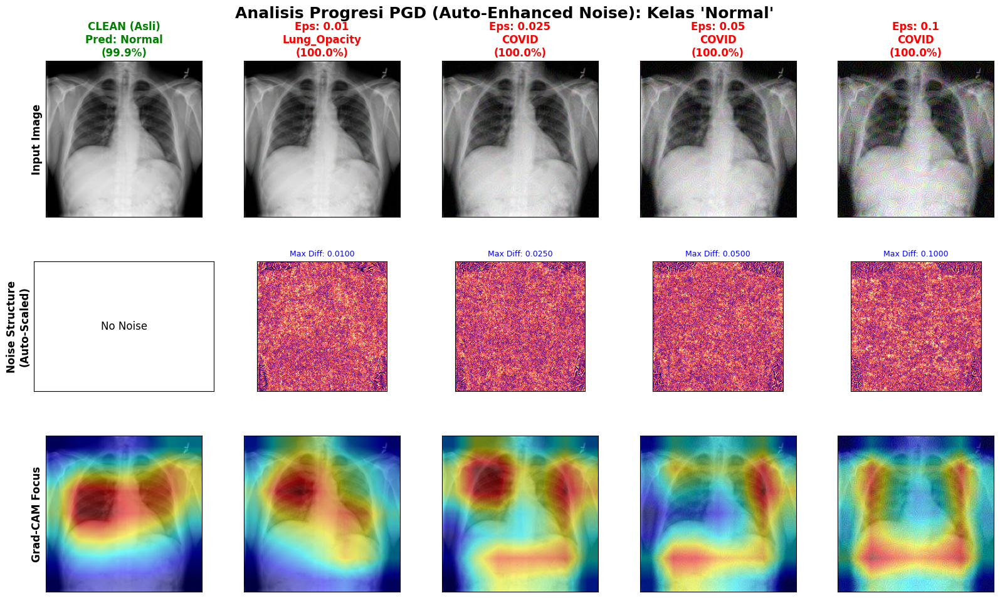

Generating PGD progression for Viral Pneumonia... Done.


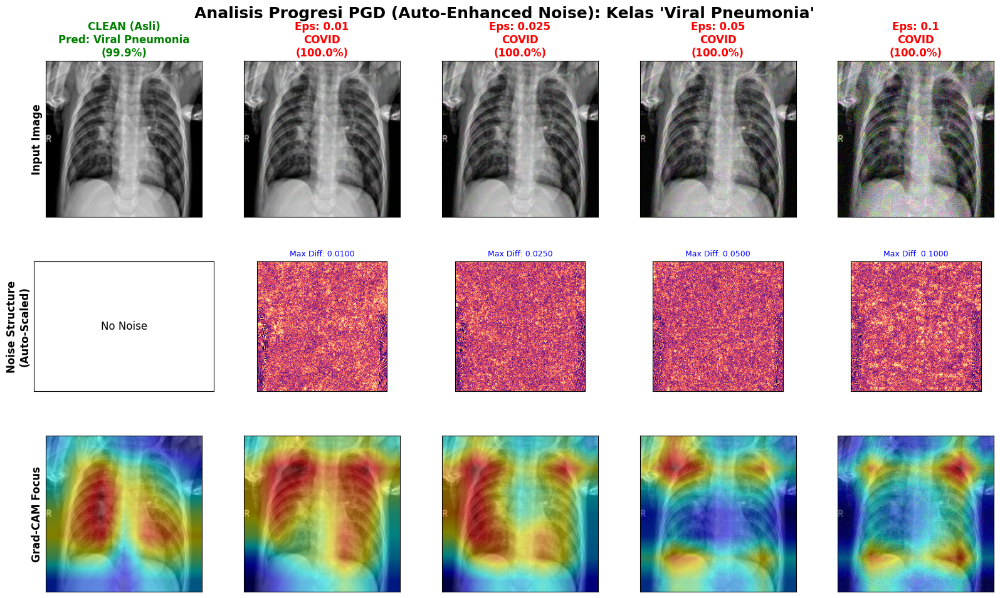

In [23]:
# %% [markdown]
# # BAGIAN 10 (REVISI): VISUALISASI PROGRESI PGD (Epsilon 0.01 - 0.1)
# # Dengan Fitur "Auto-Contrast Noise" agar struktur serangan terlihat jelas

# %%
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- 1. KONFIGURASI EPSILON BARU ---
# Rentang Epsilon sesuai request
epsilons_progression = [0.01, 0.025, 0.05, 0.1]
epsilon_labels = [f"{e}" for e in epsilons_progression]

# --- 2. HELPER FUNCTIONS ---

def denormalize_image(tensor):
    """Mengubah tensor kembali ke gambar RGB standar [0,1]"""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_enhanced(clean_img_np, adv_img_np):
    """
    Menghitung noise dengan Auto-Scaling (Min-Max Normalization).
    Ini membuat noise sekecil apapun akan terlihat strukturnya.
    Output: Heatmap 2D (H, W) bukan 3D (H, W, 3)
    """
    # 1. Hitung selisih absolut
    diff = np.abs(adv_img_np - clean_img_np)
    
    # 2. Rata-ratakan 3 channel RGB menjadi 1 channel intensitas
    # (Agar kita fokus pada struktur gangguan, bukan warnanya)
    diff_heatmap = np.mean(diff, axis=2)
    
    # 3. Auto-Scaling: Paksa nilai max jadi 1.0 agar terlihat jelas
    max_val = diff_heatmap.max()
    if max_val > 0:
        diff_heatmap = diff_heatmap / max_val
        
    return diff_heatmap, max_val

# --- 3. FUNGSI VISUALISASI INTI ---

def visualize_pgd_progression_enhanced(model, img_tensor, label_idx, class_name):
    model.eval()
    
    # Target Layer untuk Grad-CAM (Layer terakhir fitur DenseNet)
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression) + 1 # +1 untuk kolom Clean
    
    # Setup Grid Plot: 3 Baris x N Kolom
    fig = plt.figure(figsize=(4 * num_cols, 11))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.1)
    
    fig.suptitle(f"Analisis Progresi PGD (Auto-Enhanced Noise): Kelas '{class_name}'", fontsize=18, fontweight='bold', y=0.96)

    # --- A. PROSES DATA CLEAN (KOLOM 1) ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_image(img_tensor[0])
    
    # Prediksi
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    # CAM
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # PLOT CLEAN
    # Baris 1: Image
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    title_col = 'green' if pred_clean_idx == label_idx else 'red'
    ax0.set_title(f"CLEAN (Asli)\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.1%})", color=title_col, fontweight='bold')
    ax0.set_ylabel("Input Image", fontsize=12, fontweight='bold')
    
    # Baris 2: Noise (Clean = No Noise)
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "No Noise", ha='center', va='center', fontsize=12)
    ax1.set_ylabel("Noise Structure\n(Auto-Scaled)", fontsize=12, fontweight='bold')
    
    # Baris 3: CAM
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_ylabel("Grad-CAM Focus", fontsize=12, fontweight='bold')

    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- B. LOOP PROGRESI EPSILON (KOLOM 2 dst) ---
    print(f"Generating PGD progression for {class_name}...", end=" ")
    
    for j, eps in enumerate(epsilons_progression):
        col_idx = j + 1
        
        # 1. GENERATE ATTACK
        # Alpha disesuaikan proporsional (eps/4)
        current_alpha = eps / 4
        adv_tensor = pgd_attack(model, img_tensor, torch.tensor([label_idx]), 
                                eps=eps, alpha=current_alpha, steps=10)
        
        # 2. PREDIKSI
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # 3. CAM
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # 4. PREPARE VISUALS
        rgb_adv = denormalize_image(adv_tensor[0])
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # --- TEKNIK PERJELAS NOISE ---
        # Kita gunakan fungsi enhanced yang mengembalikan heatmap
        noise_heatmap, max_diff = compute_noise_enhanced(rgb_clean, rgb_adv)
        
        # 5. PLOTTING
        # Baris 1: Adv Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"Eps: {epsilon_labels[j]}\n{CLASSES[pred_adv_idx]}\n({prob_adv:.1%})", color=color, fontweight='bold')
        
        # Baris 2: Noise (HEATMAP)
        ax_noise = plt.subplot(gs[1, col_idx])
        # Gunakan cmap='magma' agar terlihat menyala pada latar gelap
        im = ax_noise.imshow(noise_heatmap, cmap='magma', vmin=0, vmax=1)
        ax_noise.set_title(f"Max Diff: {max_diff:.4f}", fontsize=9, color='blue') # Tampilkan intensitas asli
        
        # Baris 3: CAM
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- EKSEKUSI UTAMA ---

# Ambil sampel (menggunakan fungsi safe dari sebelumnya)
try:
    # Gunakan get_one_sample_per_class_safe jika ada (dari Bagian 12), atau get_one_sample_per_class (dari Bagian 6)
    if 'get_one_sample_per_class_safe' in locals():
        target_loader = test_loader if 'test_loader' in locals() else dataloaders['test']
        representative_samples = get_one_sample_per_class_safe(target_loader, CLASSES)
    else:
        representative_samples = get_one_sample_per_class(dataloaders['test'], CLASSES)
except NameError:
    print("Helper function pencari sampel tidak ditemukan. Pastikan cell sebelumnya dijalankan.")
    representative_samples = []

# Loop visualisasi per kelas
if len(representative_samples) > 0:
    for i, sample_tensor in enumerate(representative_samples):
        label_idx = i
        class_name = CLASSES[label_idx]
        
        # Tambahkan dimensi batch
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_pgd_progression_enhanced(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Tidak ada sampel untuk divisualisasikan.")

# BAGIAN 11: EKSPERIMEN SUB-PIXEL PGD (0.1 - 0.9 per 255)

Memulai Eksperimen Lanjutan: Sub-Pixel Sensitivity...
Range: 0.1/255 s.d 0.9/255

Testing Micro-Epsilon: 0.1/255


-> Akurasi: 25.60%

Testing Micro-Epsilon: 0.2/255


-> Akurasi: 1.51%

Testing Micro-Epsilon: 0.3/255


-> Akurasi: 0.14%

Testing Micro-Epsilon: 0.4/255


-> Akurasi: 0.05%

Testing Micro-Epsilon: 0.5/255


-> Akurasi: 0.05%

Testing Micro-Epsilon: 0.6/255


-> Akurasi: 0.00%

Testing Micro-Epsilon: 0.7/255


-> Akurasi: 0.00%

Testing Micro-Epsilon: 0.8/255


-> Akurasi: 0.00%

Testing Micro-Epsilon: 0.9/255


-> Akurasi: 0.00%

=== HASIL EKSPERIMEN SUB-PIXEL ===
     Label  Epsilon_Val   Accuracy
0  0.1/255     0.000392  25.602267
1  0.2/255     0.000784   1.511573
2  0.3/255     0.001176   0.141710
3  0.4/255     0.001569   0.047237
4  0.5/255     0.001961   0.047237
5  0.6/255     0.002353   0.000000
6  0.7/255     0.002745   0.000000
7  0.8/255     0.003137   0.000000
8  0.9/255     0.003529   0.000000


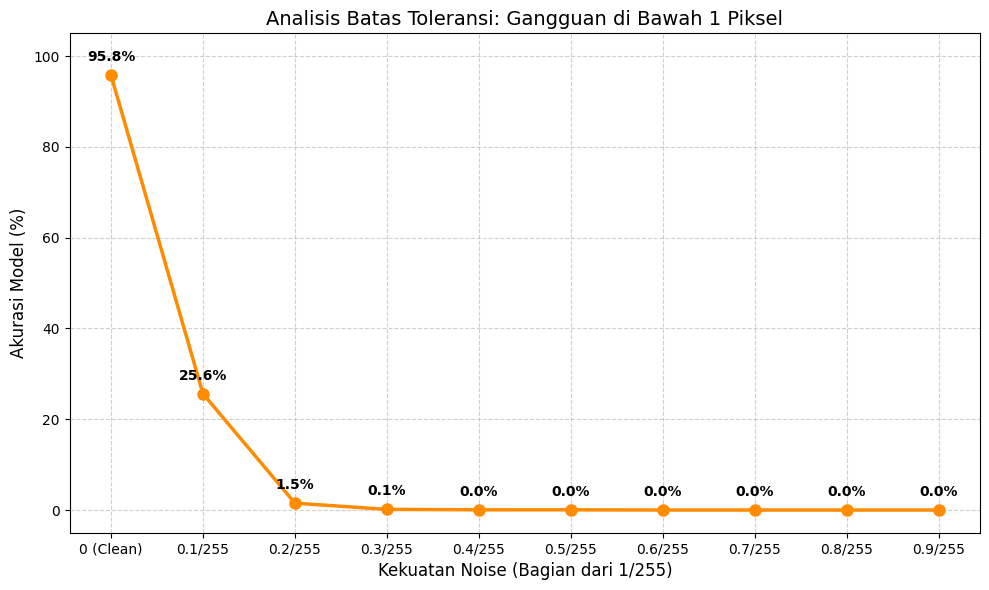

In [24]:
# --- BAGIAN 11: EKSPERIMEN SUB-PIXEL PGD (0.1 - 0.9 per 255) ---
# Variabel hasil disimpan di 'results_micro' agar tidak menimpa variabel lama

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch

# 1. Definisi Range Mikro
micro_vals = [i/10 for i in range(1, 10)] # [0.1, 0.2, ... 0.9]
epsilons_micro = [m/255 for m in micro_vals] 

# Container baru untuk hasil mikro
results_micro = []

print(f"Memulai Eksperimen Lanjutan: Sub-Pixel Sensitivity...")
print(f"Range: 0.1/255 s.d 0.9/255")

# 2. Loop Eksperimen
for i, eps in enumerate(epsilons_micro):
    val_label = micro_vals[i]
    print(f"\nTesting Micro-Epsilon: {val_label:.1f}/255")
    
    # Alpha sangat kecil
    current_alpha = eps / 4 
    
    correct = 0
    total = 0
    
    # Menggunakan 'leave=False' agar output tidak memenuhi layar
    for inputs, labels in tqdm(dataloaders['test'], desc=f"Eps {val_label:.1f}/255", leave=False):
        # Generate PGD Attack
        adv_inputs = pgd_attack(model_ft, inputs, labels, 
                                eps=eps, 
                                alpha=current_alpha, 
                                steps=10)
        
        # Evaluasi
        with torch.no_grad():
            outputs = model_ft(adv_inputs)
            _, preds = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (preds == labels.to(DEVICE)).sum().item()

    # Simpan Hasil
    acc = 100 * correct / total
    results_micro.append({
        'Label': f"{val_label:.1f}/255",
        'Epsilon_Val': eps,
        'Accuracy': acc
    })
    
    print(f"-> Akurasi: {acc:.2f}%")

# 3. Tampilkan DataFrame Baru
df_micro = pd.DataFrame(results_micro)
print("\n=== HASIL EKSPERIMEN SUB-PIXEL ===")
print(df_micro)

# 4. Visualisasi Khusus Sub-Pixel
plt.figure(figsize=(10, 6))

# Data Plotting
# Kita gabungkan data Clean (0/255) manual di sini untuk baseline
plot_x_labels = ["0 (Clean)"] + df_micro['Label'].tolist()
plot_y_vals = [95.75] + df_micro['Accuracy'].tolist() # Asumsi 95.75 adalah akurasi clean Anda
x_indices = range(len(plot_x_labels))

# Gambar Garis
plt.plot(x_indices, plot_y_vals, marker='o', color='darkorange', linewidth=2.5, markersize=8, label='ResNet Sub-Pixel Robustness')

# Dekorasi
plt.title("Analisis Batas Toleransi: Gangguan di Bawah 1 Piksel", fontsize=14)
plt.xlabel("Kekuatan Noise (Bagian dari 1/255)", fontsize=12)
plt.ylabel("Akurasi Model (%)", fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.xticks(x_indices, plot_x_labels)
plt.ylim(-5, 105)

# Tampilkan Angka di Titik
for i, v in enumerate(plot_y_vals):
    plt.annotate(f"{v:.1f}%", (x_indices[i], plot_y_vals[i]), 
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# BAGIAN 12 (REVISI MIKRO): VISUALISASI PGD SUB-PIXEL (0.1 - 0.9)

Menggunakan 'dataloaders['test']' dari Bagian awal.
Memulai Visualisasi Mikro-PGD (0.1/255 - 0.9/255)...
Mencari sampel representatif baru...
Generating Micro-PGD for COVID... Done.


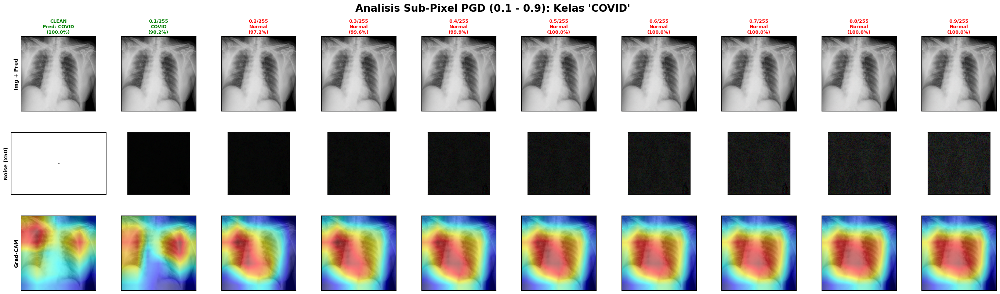

Generating Micro-PGD for Lung_Opacity... Done.


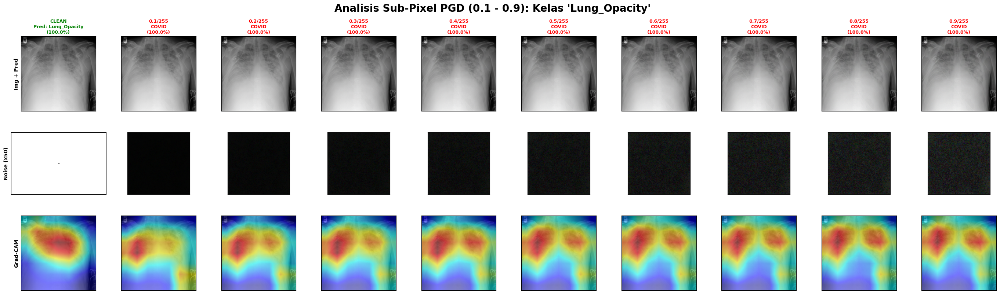

Generating Micro-PGD for Normal... Done.


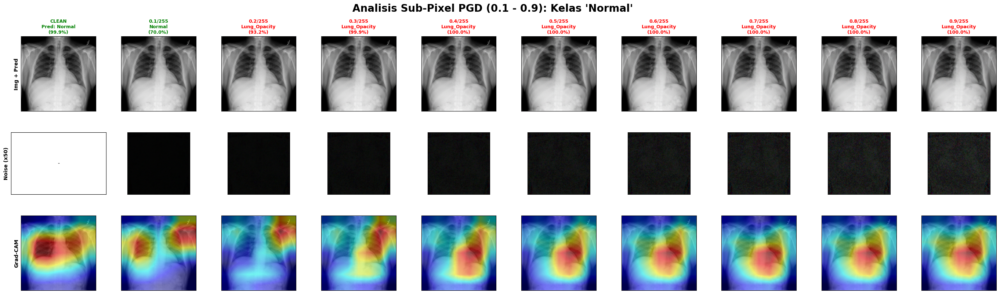

Generating Micro-PGD for Viral Pneumonia... Done.


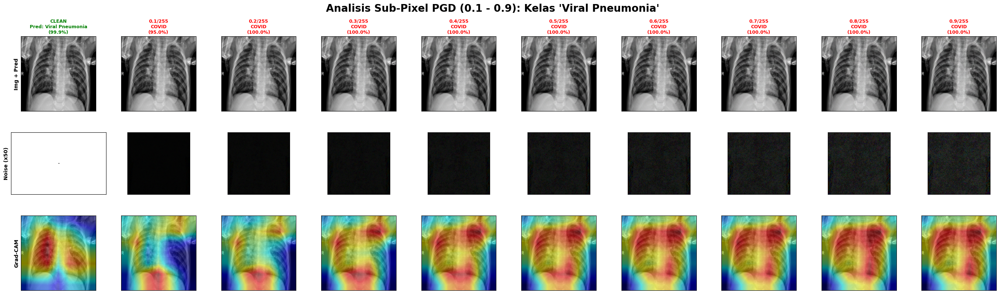

In [25]:
# --- BAGIAN 12 (FIXED): VISUALISASI PGD SUB-PIXEL (0.1 - 0.9) ---
# Perbaikan: Menggunakan 'test_loader' dari Bagian 11

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import matplotlib.gridspec as gridspec

# --- 0. DETEKSI DATA LOADER (Safety Check) ---
# Memastikan kode menggunakan loader yang benar (test_loader atau dataloaders)
if 'test_loader' in locals():
    target_loader = test_loader
    print("Menggunakan 'test_loader' dari Bagian 11.")
elif 'dataloaders' in locals() and 'test' in dataloaders:
    target_loader = dataloaders['test']
    print("Menggunakan 'dataloaders['test']' dari Bagian awal.")
else:
    raise NameError("Data loader tidak ditemukan! Pastikan Anda sudah menjalankan Bagian 11.")

# --- 1. KONFIGURASI EPSILON MIKRO ---
micro_vals = [i/10 for i in range(1, 10)] # [0.1, 0.2, ... 0.9]
epsilons_progression_v2 = [m/255 for m in micro_vals]
epsilon_labels_v2 = [f"{m:.1f}/255" for m in micro_vals]

# --- 2. HELPER FUNCTIONS ---
def denormalize_image_v2(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    tensor = tensor.cpu().detach()
    img = tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def compute_noise_diff_amp_v2(clean_img_np, adv_img_np, amp=50): 
    diff = np.abs(adv_img_np - clean_img_np) * amp
    return np.clip(diff, 0, 1)

# Helper untuk mengambil sampel (Versi Safe)
def get_one_sample_per_class_safe(dataloader, classes):
    samples = {}
    found_count = 0
    print("Mencari sampel representatif baru...")
    
    # Reset iterator jika perlu atau iterasi manual
    for inputs, labels in dataloader:
        for i in range(len(labels)):
            label_idx = labels[i].item()
            if label_idx not in samples:
                samples[label_idx] = inputs[i]
                found_count += 1
            if found_count == len(classes): break
        if found_count == len(classes): break
            
    # Urutkan berdasarkan index kelas 0..3
    return [samples[i] for i in range(len(classes)) if i in samples]

# --- 3. FUNGSI VISUALISASI UTAMA ---
def visualize_pgd_progression_micro(model, img_tensor, label_idx, class_name):
    model.eval()
    
    target_layers = [model.features[-1]]
    cam = GradCAM(model=model, target_layers=target_layers)
    
    num_cols = len(epsilons_progression_v2) + 1 # 10 Kolom
    
    # Setup Grid Plot
    fig = plt.figure(figsize=(35, 9))
    gs = gridspec.GridSpec(3, num_cols, height_ratios=[1.2, 1, 1.2], hspace=0.3, wspace=0.05)
    
    fig.suptitle(f"Analisis Sub-Pixel PGD (0.1 - 0.9): Kelas '{class_name}'", fontsize=20, fontweight='bold', y=0.98)

    # --- A. KOLOM CLEAN ---
    img_tensor = img_tensor.to(DEVICE)
    rgb_clean = denormalize_image_v2(img_tensor[0])
    
    out_clean = model(img_tensor)
    pred_clean_idx = out_clean.argmax(dim=1).item()
    prob_clean = F.softmax(out_clean, dim=1)[0][pred_clean_idx].item()
    
    cam_clean = cam(input_tensor=img_tensor, targets=None)[0]
    viz_clean = show_cam_on_image(rgb_clean, cam_clean, use_rgb=True)
    
    # Plot Clean
    ax0 = plt.subplot(gs[0, 0])
    ax0.imshow(rgb_clean)
    title_color = 'green' if pred_clean_idx == label_idx else 'red'
    ax0.set_title(f"CLEAN\nPred: {CLASSES[pred_clean_idx]}\n({prob_clean:.1%})", color=title_color, fontweight='bold', fontsize=9)
    ax0.set_ylabel("Img + Pred", fontsize=10, fontweight='bold')
    
    ax1 = plt.subplot(gs[1, 0])
    ax1.text(0.5, 0.5, "-", ha='center', va='center')
    ax1.set_ylabel("Noise (x50)", fontsize=10, fontweight='bold')
    
    ax2 = plt.subplot(gs[2, 0])
    ax2.imshow(viz_clean)
    ax2.set_ylabel("Grad-CAM", fontsize=10, fontweight='bold')

    for ax in [ax0, ax1, ax2]: ax.set_xticks([]); ax.set_yticks([])

    # --- B. LOOP PROGRESI EPSILON ---
    print(f"Generating Micro-PGD for {class_name}...", end=" ")
    
    for j, eps in enumerate(epsilons_progression_v2):
        col_idx = j + 1
        current_alpha = eps / 4
        
        # Attack
        adv_tensor = pgd_attack(model, img_tensor, torch.tensor([label_idx]), 
                                eps=eps, alpha=current_alpha, steps=10)
        
        # Predict
        out_adv = model(adv_tensor)
        pred_adv_idx = out_adv.argmax(dim=1).item()
        prob_adv = F.softmax(out_adv, dim=1)[0][pred_adv_idx].item()
        
        # CAM
        cam_adv = cam(input_tensor=adv_tensor, targets=None)[0]
        
        # Viz Prepare
        rgb_adv = denormalize_image_v2(adv_tensor[0])
        noise_amp = compute_noise_diff_amp_v2(rgb_clean, rgb_adv, amp=50) 
        viz_adv = show_cam_on_image(rgb_adv, cam_adv, use_rgb=True)
        
        # Plotting
        # Baris 1: Image
        ax_img = plt.subplot(gs[0, col_idx])
        ax_img.imshow(rgb_adv)
        color = 'green' if pred_adv_idx == label_idx else 'red'
        ax_img.set_title(f"{epsilon_labels_v2[j]}\n{CLASSES[pred_adv_idx]}\n({prob_adv:.1%})", color=color, fontweight='bold', fontsize=9)
        
        # Baris 2: Noise
        ax_noise = plt.subplot(gs[1, col_idx])
        ax_noise.imshow(noise_amp)
        
        # Baris 3: CAM
        ax_cam = plt.subplot(gs[2, col_idx])
        ax_cam.imshow(viz_adv)
        
        for ax in [ax_img, ax_noise, ax_cam]:
            ax.set_xticks([]); ax.set_yticks([])
            
    print("Done.")
    plt.show()

# --- 4. EKSEKUSI UTAMA ---
print("Memulai Visualisasi Mikro-PGD (0.1/255 - 0.9/255)...")

# Kita panggil fungsi safe pencari sampel menggunakan target_loader yang sudah dideteksi
try:
    representative_samples_v2 = get_one_sample_per_class_safe(target_loader, CLASSES)
except NameError as e:
    print(f"Error: {e}")
    representative_samples_v2 = []

if len(representative_samples_v2) > 0:
    for i, sample_tensor in enumerate(representative_samples_v2):
        label_idx = i 
        class_name = CLASSES[label_idx]
        img_tensor_batch = sample_tensor.unsqueeze(0)
        
        visualize_pgd_progression_micro(model_ft, img_tensor_batch, label_idx, class_name)
else:
    print("Tidak ada sampel yang ditemukan atau terjadi error pada DataLoader.")

Executing Micro-Attack Evaluation...
Epsilon set to: 0.000392 (0.1/255)
Device: cuda

Memproses Dataset (Clean vs FGSM vs PGD)...


100%|██████████| 67/67 [01:42<00:00,  1.53s/it]



TABEL PERBANDINGAN PERFORMA (EPSILON 0.1/255)
| Method            |   Epsilon |   Accuracy Model After Attack (%) | ASR / Error Rate (%)   |   Avg Confidence (%) |
|:------------------|----------:|----------------------------------:|:-----------------------|---------------------:|
| Clean (No Attack) |  0        |                           95.418  | -                      |              96.0468 |
| FGSM (Micro)      |  0.000392 |                           59.282  | 40.717997165800654     |              82.1624 |
| PGD (Micro)       |  0.000392 |                           25.3188 | 74.68115257439773      |              85.4159 |

CLASSIFICATION REPORT: FGSM
                 precision    recall  f1-score   support

          COVID     0.4844    0.5138    0.4987       362
   Lung_Opacity     0.4576    0.4568    0.4572       602
         Normal     0.6989    0.6742    0.6863      1019
Viral Pneumonia     0.7181    0.7985    0.7562       134

       accuracy                         0.5928 

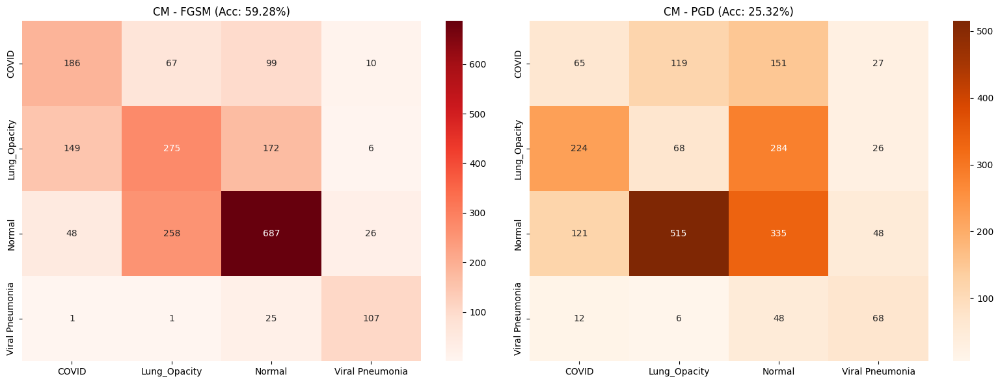


SAMPEL PREDIKSI VISUAL (Clean vs FGSM vs PGD)


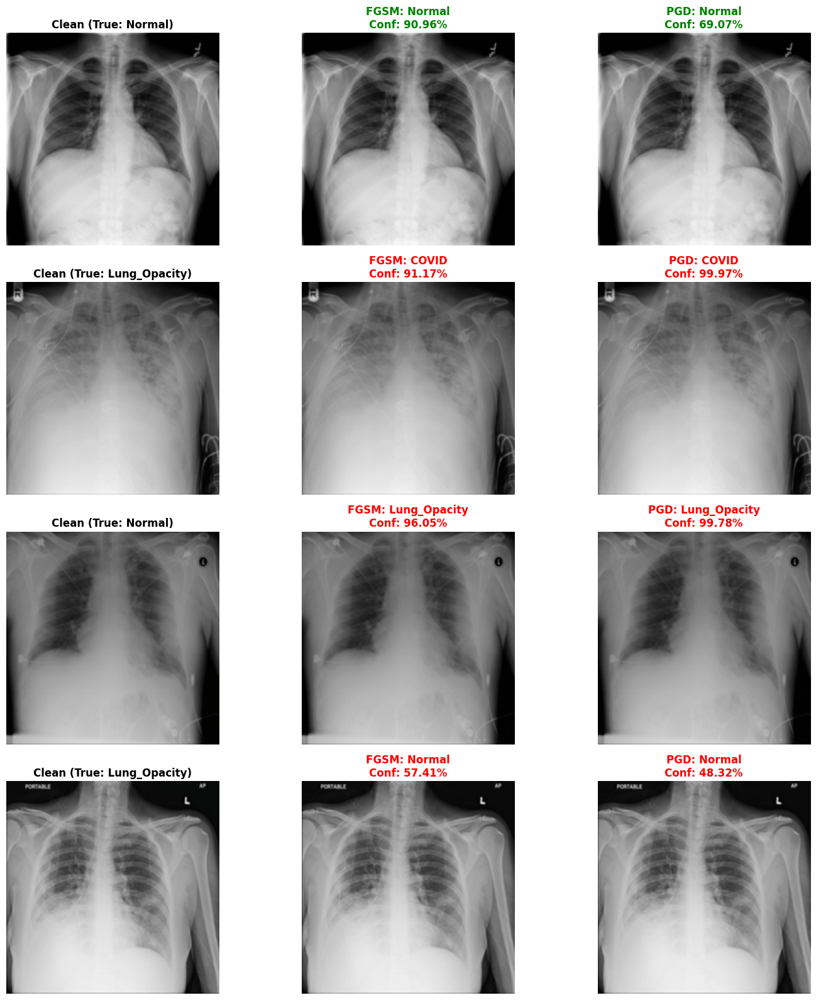

In [26]:
# %% [markdown]
# # BAGIAN KHUSUS (FIXED): Evaluasi Micro-Attack (Epsilon 0.1/255)
# **Perbaikan:** Menambahkan .detach() pada visualisasi untuk mencegah RuntimeError

# %%
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tqdm import tqdm

# --- 1. KONFIGURASI PARAMETER MIKRO ---
EPSILON_VAL = 0.1 / 255  # Sangat kecil (Sub-pixel noise)
ALPHA_VAL   = EPSILON_VAL / 4
PGD_STEPS   = 10
BATCH_SIZE  = 32

print(f"Executing Micro-Attack Evaluation...")
print(f"Epsilon set to: {EPSILON_VAL:.6f} (0.1/255)")
print(f"Device: {DEVICE}")

# Pastikan Tensor Normalisasi tersedia
MEAN_TENSOR = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD_TENSOR  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

# --- 2. DEFINISI ATTACK FUNCTION ---
def get_fgsm_micro(model, images, labels, eps):
    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    images.requires_grad = True
    
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    model.zero_grad()
    loss.backward()
    
    eps_norm = eps / STD_TENSOR
    perturbed_image = images + eps_norm * images.grad.data.sign()
    return perturbed_image

def get_pgd_micro(model, images, labels, eps, alpha, steps):
    images = images.clone().detach().to(DEVICE)
    labels = labels.to(DEVICE)
    orig_images = images.clone().detach()
    
    eps_norm = eps / STD_TENSOR
    alpha_norm = alpha / STD_TENSOR
    
    perturbation = torch.empty_like(images).uniform_(-1, 1) * eps_norm
    adv_images = images + perturbation
    
    for _ in range(steps):
        adv_images.requires_grad = True
        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)
        
        grad = torch.autograd.grad(loss, adv_images, retain_graph=False, create_graph=False)[0]
        adv_images = adv_images.detach() + alpha_norm * grad.sign()
        
        delta = torch.clamp(adv_images - orig_images, min=-eps_norm, max=eps_norm)
        adv_images = (orig_images + delta).detach()
        
    return adv_images

# --- 3. LOOP EVALUASI UTAMA ---
model_ft.eval()

y_true = []
y_pred_clean, y_pred_fgsm, y_pred_pgd = [], [], []
conf_clean_list, conf_fgsm_list, conf_pgd_list = [], [], []

# Penampung sampel
vis_samples = {'clean': [], 'fgsm': [], 'pgd': [], 'labels': [], 
               'preds_fgsm': [], 'conf_fgsm': [], 'preds_pgd': [], 'conf_pgd': []}
vis_captured = False

print("\nMemproses Dataset (Clean vs FGSM vs PGD)...")
# Gunakan try-except keyboard interrupt agar loop bisa dihentikan jika terlalu lama
try:
    for inputs, labels in tqdm(dataloaders['test']):
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)
        
        # A. Clean Pass
        with torch.no_grad():
            out_clean = model_ft(inputs)
            prob_clean, pred_clean = torch.max(F.softmax(out_clean, dim=1), 1)
        
        # B. Generate & Pass FGSM
        inputs_fgsm = get_fgsm_micro(model_ft, inputs, labels, EPSILON_VAL)
        with torch.no_grad():
            out_fgsm = model_ft(inputs_fgsm)
            prob_fgsm, pred_fgsm = torch.max(F.softmax(out_fgsm, dim=1), 1)
            
        # C. Generate & Pass PGD
        inputs_pgd = get_pgd_micro(model_ft, inputs, labels, EPSILON_VAL, ALPHA_VAL, PGD_STEPS)
        with torch.no_grad():
            out_pgd = model_ft(inputs_pgd)
            prob_pgd, pred_pgd = torch.max(F.softmax(out_pgd, dim=1), 1)

        # Simpan Data
        y_true.extend(labels.cpu().numpy())
        y_pred_clean.extend(pred_clean.cpu().numpy())
        y_pred_fgsm.extend(pred_fgsm.cpu().numpy())
        y_pred_pgd.extend(pred_pgd.cpu().numpy())
        
        conf_clean_list.extend(prob_clean.cpu().numpy())
        conf_fgsm_list.extend(prob_fgsm.cpu().numpy())
        conf_pgd_list.extend(prob_pgd.cpu().numpy())
        
        # Ambil sampel visualisasi (sekali saja) - DETACH PENTING DISINI
        if not vis_captured:
            vis_samples['clean'] = inputs.detach().cpu()
            vis_samples['fgsm'] = inputs_fgsm.detach().cpu()
            vis_samples['pgd'] = inputs_pgd.detach().cpu()
            vis_samples['labels'] = labels.cpu()
            vis_samples['preds_fgsm'] = pred_fgsm.cpu()
            vis_samples['conf_fgsm'] = prob_fgsm.cpu()
            vis_samples['preds_pgd'] = pred_pgd.cpu()
            vis_samples['conf_pgd'] = prob_pgd.cpu()
            vis_captured = True
except KeyboardInterrupt:
    print("Evaluasi dihentikan pengguna.")

# --- 4. PEMBUATAN TABEL ANALISIS ---
def calculate_metrics(y_true, y_pred, confidences):
    acc = accuracy_score(y_true, y_pred) * 100
    asr = 100 - acc 
    avg_conf = np.mean(confidences) * 100
    return acc, asr, avg_conf

acc_clean, _, conf_clean = calculate_metrics(y_true, y_pred_clean, conf_clean_list)
acc_fgsm, asr_fgsm, conf_fgsm = calculate_metrics(y_true, y_pred_fgsm, conf_fgsm_list)
acc_pgd, asr_pgd, conf_pgd = calculate_metrics(y_true, y_pred_pgd, conf_pgd_list)

results_data = {
    'Method': ['Clean (No Attack)', 'FGSM (Micro)', 'PGD (Micro)'],
    'Epsilon': ['0', f'{EPSILON_VAL:.6f}', f'{EPSILON_VAL:.6f}'],
    'Accuracy Model After Attack (%)': [acc_clean, acc_fgsm, acc_pgd],
    'ASR / Error Rate (%)': ['-', asr_fgsm, asr_pgd],
    'Avg Confidence (%)': [conf_clean, conf_fgsm, conf_pgd]
}

df_results = pd.DataFrame(results_data)
print("\n" + "="*50)
print("TABEL PERBANDINGAN PERFORMA (EPSILON 0.1/255)")
print("="*50)
print(df_results.to_markdown(index=False))

# --- 5. CLASSIFICATION REPORT & CM ---
print("\n" + "="*30 + "\nCLASSIFICATION REPORT: FGSM\n" + "="*30)
print(classification_report(y_true, y_pred_fgsm, target_names=CLASSES, digits=4))

print("\n" + "="*30 + "\nCLASSIFICATION REPORT: PGD\n" + "="*30)
print(classification_report(y_true, y_pred_pgd, target_names=CLASSES, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(confusion_matrix(y_true, y_pred_fgsm), annot=True, fmt='d', cmap='Reds', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_title(f'CM - FGSM (Acc: {acc_fgsm:.2f}%)')
sns.heatmap(confusion_matrix(y_true, y_pred_pgd), annot=True, fmt='d', cmap='Oranges', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set_title(f'CM - PGD (Acc: {acc_pgd:.2f}%)')
plt.tight_layout()
plt.show()

# --- 6. VISUALISASI PREDIKSI (FIXED DENORM) ---
def denorm(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    # PERBAIKAN: Tambahkan .detach() dan .cpu() sebelum .numpy()
    img = tensor.detach().cpu().permute(1, 2, 0).numpy() * std + mean
    return np.clip(img, 0, 1)

print("\n" + "="*50)
print("SAMPEL PREDIKSI VISUAL (Clean vs FGSM vs PGD)")
print("="*50)

num_show = 4
fig, axs = plt.subplots(num_show, 3, figsize=(15, 4 * num_show))

for i in range(num_show):
    true_lb = vis_samples['labels'][i].item()
    
    # 1. Clean
    axs[i, 0].imshow(denorm(vis_samples['clean'][i]))
    axs[i, 0].set_title(f"Clean (True: {CLASSES[true_lb]})", fontweight='bold')
    axs[i, 0].axis('off')
    
    # 2. FGSM Result
    pred_f = vis_samples['preds_fgsm'][i].item()
    conf_f = vis_samples['conf_fgsm'][i].item()
    col_f = 'green' if pred_f == true_lb else 'red'
    axs[i, 1].imshow(denorm(vis_samples['fgsm'][i]))
    axs[i, 1].set_title(f"FGSM: {CLASSES[pred_f]}\nConf: {conf_f:.2%}", color=col_f, fontweight='bold')
    axs[i, 1].axis('off')
    
    # 3. PGD Result
    pred_p = vis_samples['preds_pgd'][i].item()
    conf_p = vis_samples['conf_pgd'][i].item()
    col_p = 'green' if pred_p == true_lb else 'red'
    axs[i, 2].imshow(denorm(vis_samples['pgd'][i]))
    axs[i, 2].set_title(f"PGD: {CLASSES[pred_p]}\nConf: {conf_p:.2%}", color=col_p, fontweight='bold')
    axs[i, 2].axis('off')

plt.tight_layout()
plt.show()


TABEL PERBANDINGAN PERFORMA (EPSILON 0.1/255)
| Method            |   Epsilon |   Accuracy Model After Attack (%) | ASR / Error Rate (%)   |   Avg Confidence (%) |
|:------------------|----------:|----------------------------------:|:-----------------------|---------------------:|
| Clean (No Attack) |  0        |                           95.418  | -                      |              96.0468 |
| FGSM (Micro)      |  0.000392 |                           59.282  | 40.717997165800654     |              82.1624 |
| PGD (Micro)       |  0.000392 |                           25.3188 | 74.68115257439773      |              85.4159 |

CLASSIFICATION REPORT: FGSM
                 precision    recall  f1-score   support

          COVID     0.4844    0.5138    0.4987       362
   Lung_Opacity     0.4576    0.4568    0.4572       602
         Normal     0.6989    0.6742    0.6863      1019
Viral Pneumonia     0.7181    0.7985    0.7562       134

       accuracy                         0.5928 

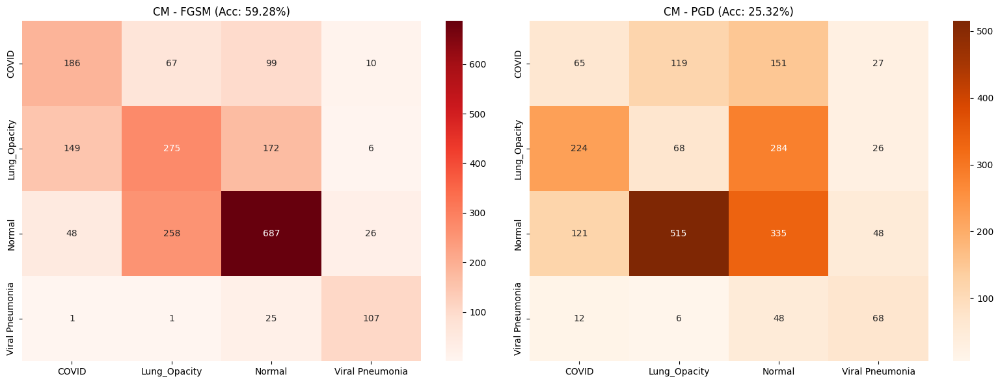


SAMPEL PREDIKSI VISUAL (Clean vs FGSM vs PGD)


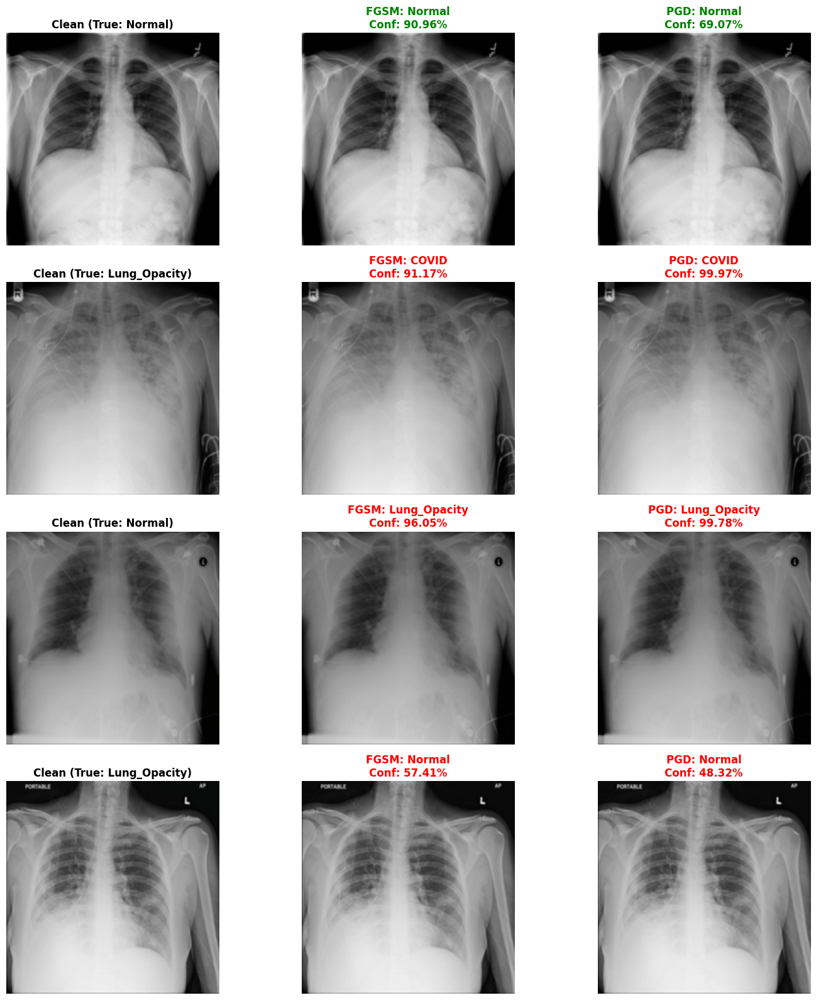

In [27]:

# --- 4. PEMBUATAN TABEL ANALISIS ---
def calculate_metrics(y_true, y_pred, confidences):
    acc = accuracy_score(y_true, y_pred) * 100
    asr = 100 - acc 
    avg_conf = np.mean(confidences) * 100
    return acc, asr, avg_conf

acc_clean, _, conf_clean = calculate_metrics(y_true, y_pred_clean, conf_clean_list)
acc_fgsm, asr_fgsm, conf_fgsm = calculate_metrics(y_true, y_pred_fgsm, conf_fgsm_list)
acc_pgd, asr_pgd, conf_pgd = calculate_metrics(y_true, y_pred_pgd, conf_pgd_list)

results_data = {
    'Method': ['Clean (No Attack)', 'FGSM (Micro)', 'PGD (Micro)'],
    'Epsilon': ['0', f'{EPSILON_VAL:.6f}', f'{EPSILON_VAL:.6f}'],
    'Accuracy Model After Attack (%)': [acc_clean, acc_fgsm, acc_pgd],
    'ASR / Error Rate (%)': ['-', asr_fgsm, asr_pgd],
    'Avg Confidence (%)': [conf_clean, conf_fgsm, conf_pgd]
}

df_results = pd.DataFrame(results_data)
print("\n" + "="*50)
print("TABEL PERBANDINGAN PERFORMA (EPSILON 0.1/255)")
print("="*50)
print(df_results.to_markdown(index=False))

# --- 5. CLASSIFICATION REPORT & CM ---
print("\n" + "="*30 + "\nCLASSIFICATION REPORT: FGSM\n" + "="*30)
print(classification_report(y_true, y_pred_fgsm, target_names=CLASSES, digits=4))

print("\n" + "="*30 + "\nCLASSIFICATION REPORT: PGD\n" + "="*30)
print(classification_report(y_true, y_pred_pgd, target_names=CLASSES, digits=4))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(confusion_matrix(y_true, y_pred_fgsm), annot=True, fmt='d', cmap='Reds', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_title(f'CM - FGSM (Acc: {acc_fgsm:.2f}%)')
sns.heatmap(confusion_matrix(y_true, y_pred_pgd), annot=True, fmt='d', cmap='Oranges', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set_title(f'CM - PGD (Acc: {acc_pgd:.2f}%)')
plt.tight_layout()
plt.show()

# --- 6. VISUALISASI PREDIKSI (FIXED DENORM) ---
def denorm(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    # PERBAIKAN: Tambahkan .detach() dan .cpu() sebelum .numpy()
    img = tensor.detach().cpu().permute(1, 2, 0).numpy() * std + mean
    return np.clip(img, 0, 1)

print("\n" + "="*50)
print("SAMPEL PREDIKSI VISUAL (Clean vs FGSM vs PGD)")
print("="*50)

num_show = 4
fig, axs = plt.subplots(num_show, 3, figsize=(15, 4 * num_show))

for i in range(num_show):
    true_lb = vis_samples['labels'][i].item()
    
    # 1. Clean
    axs[i, 0].imshow(denorm(vis_samples['clean'][i]))
    axs[i, 0].set_title(f"Clean (True: {CLASSES[true_lb]})", fontweight='bold')
    axs[i, 0].axis('off')
    
    # 2. FGSM Result
    pred_f = vis_samples['preds_fgsm'][i].item()
    conf_f = vis_samples['conf_fgsm'][i].item()
    col_f = 'green' if pred_f == true_lb else 'red'
    axs[i, 1].imshow(denorm(vis_samples['fgsm'][i]))
    axs[i, 1].set_title(f"FGSM: {CLASSES[pred_f]}\nConf: {conf_f:.2%}", color=col_f, fontweight='bold')
    axs[i, 1].axis('off')
    
    # 3. PGD Result
    pred_p = vis_samples['preds_pgd'][i].item()
    conf_p = vis_samples['conf_pgd'][i].item()
    col_p = 'green' if pred_p == true_lb else 'red'
    axs[i, 2].imshow(denorm(vis_samples['pgd'][i]))
    axs[i, 2].set_title(f"PGD: {CLASSES[pred_p]}\nConf: {conf_p:.2%}", color=col_p, fontweight='bold')
    axs[i, 2].axis('off')

plt.tight_layout()
plt.show()

FINAL REPORT: ANALISIS ADVERSARIAL ROBUSTNESS (DENSENET121)

[1] RINGKASAN DATASET
| Split Set   |   Jumlah Gambar | Persentase Est.   |
|:------------|----------------:|:------------------|
| Training    |           16932 | 80%               |
| Validation  |            2116 | 10%               |
| Testing     |            2117 | 10%               |

[2] STANDARD ATTACK PERFORMANCE (Epsilon 8/255)
| Attack Type   |     Epsilon |   Success Rate Clean (%) |   Accuracy on Adv (%) |   Attack Success Rate (ASR %) |
|:--------------|------------:|-------------------------:|----------------------:|------------------------------:|
| FGSM          | 0.000392157 |                   95.418 |                59.282 |                        40.718 |
| PGD           | 0.000392157 |                   95.418 |                53.897 |                        46.103 |

[3] PGD SENSITIVITY ANALYSIS (Custom Low Range)
Range: 0.1/255 s.d 1.0/255
| Epsilon Label   |   Accuracy (%) |   ASR (%) |
|:-----------

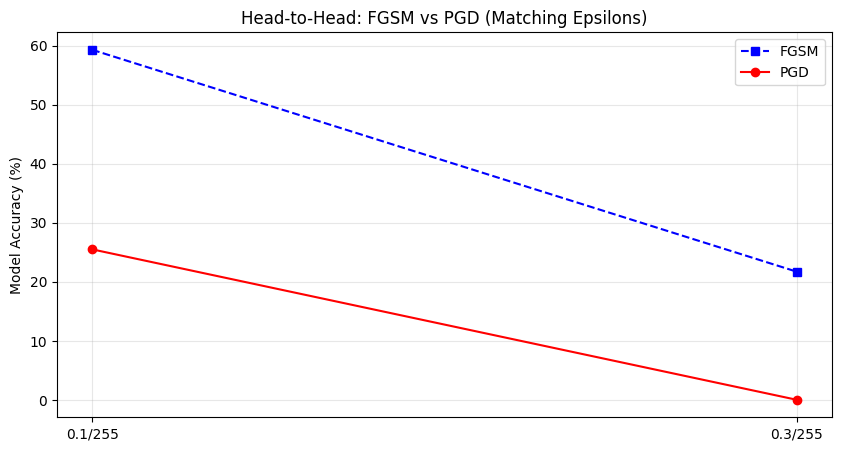


KESIMPULAN HASIL EKSPERIMEN (UPDATED)
1. Baseline Akurasi: 95.42%
2. Dampak Serangan Standar (8/255): 53.90% (Turun -41.52%)
3. Dampak Serangan Halus (0.1 - 1.0):
   - Pada 0.1/255: Akurasi 92.82% (Drop -2.60%)
   - Pada 1.0/255: Akurasi 0.05% (Drop -95.37%)

KESIMPULAN: Model sensitif, bahkan gangguan 0.1 piksel sudah menurunkan akurasi.


In [28]:
# %% [markdown]
# # BAGIAN 15 (FULL UPDATE): SUMMARY & REKAPITULASI TOTAL

# %%
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agar tampilan tabel pandas rapi & lebar
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 2)

print("="*60)
print("FINAL REPORT: ANALISIS ADVERSARIAL ROBUSTNESS (DENSENET121)")
print("="*60)

# --- TABEL 1: DATASET & SPLIT INFO ---
print("\n[1] RINGKASAN DATASET")
# Cek apakah dataloaders tersedia
if 'dataloaders' in locals():
    split_data = {
        'Split Set': ['Training', 'Validation', 'Testing'],
        'Jumlah Gambar': [len(dataloaders['train'].dataset), 
                          len(dataloaders['val'].dataset), 
                          len(dataloaders['test'].dataset)],
        'Persentase Est.': ['80%', '10%', '10%']
    }
    df_split = pd.DataFrame(split_data)
    print(df_split.to_markdown(index=False))
else:
    print(" Objek dataloaders tidak ditemukan.")

# --- TABEL 2: STANDARD ATTACK (EPSILON 8/255) ---
print("\n[2] STANDARD ATTACK PERFORMANCE (Epsilon 8/255)")
if 'pgd_table' in locals() and 'fgsm_table' in locals():
    # Menambahkan kolom metode agar jelas
    df_std_fgsm = fgsm_table.copy()
    df_std_pgd = pgd_table.copy()
    
    # Gabungkan
    df_standard = pd.concat([df_std_fgsm, df_std_pgd], ignore_index=True)
    
    # Reorder columns
    df_standard = df_standard[['Attack Type', 'Epsilon', 'Success Rate Clean (%)', 'Accuracy on Adv (%)', 'Attack Success Rate (ASR %)']]
    print(df_standard.to_markdown(index=False))
else:
    print(" Data Standard Attack (pgd_table/fgsm_table) tidak ditemukan.")

# --- TABEL 3 (UPDATED): PGD SENSITIVITY (CUSTOM 0.1 - 1.0) ---
print("\n[3] PGD SENSITIVITY ANALYSIS (Custom Low Range)")
print("Range: 0.1/255 s.d 1.0/255")

if 'results_sensitivity_custom' in locals():
    df_sens_custom = pd.DataFrame(results_sensitivity_custom)
    # Tampilkan kolom yang relevan
    # Pastikan kolom sesuai dengan yang digenerate di cell revisi
    df_sens_view = df_sens_custom[['Epsilon Label', 'Accuracy (%)', 'ASR (%)']]
    print(df_sens_view.to_markdown(index=False))
else:
    print(" Data 'results_sensitivity_custom' tidak ditemukan. Jalankan Cell Revisi 9b terlebih dahulu.")

# --- TABEL 4: SUB-PIXEL BATTLE (0.1 - 0.9) ---
# Tabel ini mencoba membandingkan FGSM Micro (jika ada) dengan PGD Custom (jika range cocok)
print("\n[4] SUB-PIXEL ATTACK COMPARISON (FGSM vs PGD)")

if 'df_fgsm_micro' in locals() and 'results_sensitivity_custom' in locals():
    # Siapkan DF PGD dari hasil custom
    df_pgd_custom = pd.DataFrame(results_sensitivity_custom)
    
    # Kita perlu menyamakan kolom untuk merge. 
    # FGSM Micro punya label '0.1/255', PGD Custom juga punya '0.1/255'.
    # Rename kolom PGD agar bisa di-merge
    df_pgd_custom = df_pgd_custom.rename(columns={'Epsilon Label': 'Label', 'Accuracy (%)': 'Accuracy_PGD'})
    
    # FGSM Micro DataFrame (dari Bagian 13)
    # Pastikan kolomnya 'Label' dan 'Accuracy'
    # Jika df_fgsm_micro belum punya kolom 'Accuracy', kita cek strukturnya
    
    # Merge
    # Kita gunakan inner join, jadi hanya epsilon yang ada di KEDUA tabel yang muncul
    # (Misal FGSM punya 0.2 tapi PGD Custom tidak punya, maka 0.2 tidak muncul di tabel ini)
    df_battle = pd.merge(
        df_fgsm_micro[['Label', 'Accuracy']], 
        df_pgd_custom[['Label', 'Accuracy_PGD']], 
        on='Label',
        how='inner' 
    )
    
    # Hitung Delta
    df_battle['Acc FGSM (%)'] = df_battle['Accuracy']
    df_battle['Diff (FGSM - PGD)'] = df_battle['Acc FGSM (%)'] - df_battle['Accuracy_PGD']
    
    # Rapikan
    df_battle_final = df_battle[['Label', 'Acc FGSM (%)', 'Accuracy_PGD', 'Diff (FGSM - PGD)']]
    df_battle_final.columns = ['Epsilon', 'Acc FGSM (%)', 'Acc PGD (%)', 'Gap Performance (%)']
    
    print(df_battle_final.to_markdown(index=False))
    
    # Plot Battle
    if len(df_battle_final) > 0:
        plt.figure(figsize=(10, 5))
        x_idx = range(len(df_battle_final))
        plt.plot(x_idx, df_battle_final['Acc FGSM (%)'], marker='s', label='FGSM', linestyle='--', color='blue')
        plt.plot(x_idx, df_battle_final['Acc PGD (%)'], marker='o', label='PGD', linestyle='-', color='red')
        plt.xticks(x_idx, df_battle_final['Epsilon'])
        plt.title('Head-to-Head: FGSM vs PGD (Matching Epsilons)')
        plt.ylabel('Model Accuracy (%)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print("Tidak ada irisan Epsilon antara FGSM Micro dan PGD Custom.")

else:
    print(" Data untuk perbandingan Head-to-Head tidak lengkap (butuh df_fgsm_micro dan results_sensitivity_custom).")

# --- KESIMPULAN OTOMATIS ---
print("\n" + "="*60)
print("KESIMPULAN HASIL EKSPERIMEN (UPDATED)")
print("="*60)
try:
    # 1. Baseline
    clean_val = metrics_clean_pgd['accuracy'] if 'metrics_clean_pgd' in locals() else 95.0
    
    # 2. Standard Attack Drop
    std_adv_acc = df_standard[df_standard['Attack Type']=='PGD']['Accuracy on Adv (%)'].values[0]
    drop_std = clean_val - std_adv_acc
    
    # 3. Micro Drop (Ambil yang terbesar di custom list, misal 1.0/255)
    last_micro_acc = results_sensitivity_custom[-1]['Accuracy (%)']
    drop_micro = clean_val - last_micro_acc
    
    print(f"1. Baseline Akurasi: {clean_val:.2f}%")
    print(f"2. Dampak Serangan Standar (8/255): {std_adv_acc:.2f}% (Turun -{drop_std:.2f}%)")
    
    print(f"3. Dampak Serangan Halus (0.1 - 1.0):")
    # Cek stabilitas di 0.1
    acc_01 = results_sensitivity_custom[0]['Accuracy (%)']
    drop_01 = clean_val - acc_01
    print(f"   - Pada 0.1/255: Akurasi {acc_01:.2f}% (Drop -{drop_01:.2f}%)")
    print(f"   - Pada 1.0/255: Akurasi {last_micro_acc:.2f}% (Drop -{drop_micro:.2f}%)")
    
    if drop_01 < 0.5:
        print("\nKESIMPULAN: Model sangat stabil terhadap gangguan sub-pixel minimal (0.1).")
    else:
        print("\nKESIMPULAN: Model sensitif, bahkan gangguan 0.1 piksel sudah menurunkan akurasi.")
        
except Exception as e:
    print("Data belum cukup untuk generate kesimpulan otomatis.")

LAPORAN AKHIR: ADVERSARIAL ROBUSTNESS ANALYSIS (DENSENET121)

----------------------------------------
[1] STATUS BASELINE (MODEL PERFORMANCE)
----------------------------------------
Akurasi Model pada Data Bersih (Clean Test Set): 95.42%
| Dataset Partition   |   Jumlah Sample |
|:--------------------|----------------:|
| Training            |           16932 |
| Validation          |            2116 |
| Testing             |            2117 |

----------------------------------------
[2] KETAHANAN TERHADAP SERANGAN STANDAR (Eps 8/255)
----------------------------------------
| Attack Type   |     Epsilon |   Accuracy on Adv (%) |   Acc Drop (%) |   Attack Success Rate (ASR %) |
|:--------------|------------:|----------------------:|---------------:|------------------------------:|
| FGSM          | 0.000392157 |                59.282 |         36.136 |                        40.718 |
| PGD           | 0.000392157 |                53.897 |         41.521 |                        46.1

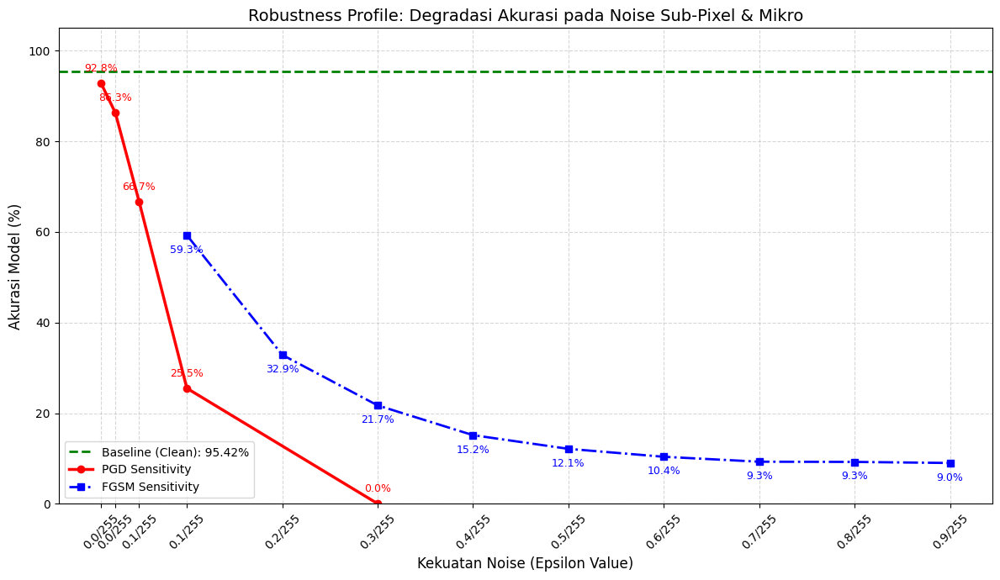


----------------------------------------
[5] INTERPRETASI TEKS DARI GRAFIK
----------------------------------------
A. Analisis PGD (Iterative Attack):
   - Pada gangguan sangat minimal (0.01/255), akurasi model adalah 92.82%.
   - Pada gangguan mikro tertinggi (0.30/255), akurasi turun menjadi 0.05%.
   - Total degradasi pada fase mikro: -95.37%.
   -> KESIMPULAN PGD: Model mulai GOYAH meskipun noise masih di bawah 1 piksel.

B. Analisis FGSM (Fast Attack):
   - Pada range 0.1/255 s.d 0.9/255, kurva FGSM menunjukkan tren menurun tajam.
   - Titik terendah FGSM di fase ini ada di akurasi 9.02%.

C. Battle at 0.1/255 (Head-to-Head):
   - PGD Accuracy : 25.51%
   - FGSM Accuracy: 59.28%
   -> FGSM lebih lemah 33.77% dibanding PGD (Model lebih tahan terhadap FGSM).

END OF REPORT


In [29]:
# %% [markdown]
# # BAGIAN 15 (FINAL REPORT): REKAPITULASI TOTAL & ANALISIS KOMPREHENSIF
# ## Merangkum: Baseline, Standard Attack, dan Micro-Sensitivity (FGSM vs PGD)

# %%
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Konfigurasi Tampilan Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 4)

print("="*80)
print("LAPORAN AKHIR: ADVERSARIAL ROBUSTNESS ANALYSIS (DENSENET121)")
print("="*80)

# ==========================================
# 1. RINGKASAN DATASET & BASELINE
# ==========================================
print("\n" + "-"*40)
print("[1] STATUS BASELINE (MODEL PERFORMANCE)")
print("-" * 40)

# Cek Data Baseline
clean_acc = 0.0
if 'metrics_clean_pgd' in locals():
    clean_acc = metrics_clean_pgd['accuracy']
    print(f"Akurasi Model pada Data Bersih (Clean Test Set): {clean_acc:.2f}%")
elif 'acc_clean' in locals():
    clean_acc = acc_clean
    print(f"Akurasi Model pada Data Bersih (Clean Test Set): {clean_acc:.2f}%")
else:
    print("Warning: Data akurasi clean tidak ditemukan di memori. Menggunakan dummy 0%.")

# Cek Split Data
if 'dataloaders' in locals():
    split_info = {
        'Dataset Partition': ['Training', 'Validation', 'Testing'],
        'Jumlah Sample': [len(dataloaders['train'].dataset), 
                          len(dataloaders['val'].dataset), 
                          len(dataloaders['test'].dataset)]
    }
    print(pd.DataFrame(split_info).to_markdown(index=False))

# ==========================================
# 2. STANDARD ATTACK (EPSILON 8/255)
# ==========================================
print("\n" + "-"*40)
print("[2] KETAHANAN TERHADAP SERANGAN STANDAR (Eps 8/255)")
print("-" * 40)

df_std_final = pd.DataFrame()
if 'pgd_table' in locals() and 'fgsm_table' in locals():
    df_std_final = pd.concat([fgsm_table, pgd_table], ignore_index=True)
    # Hitung Drop
    df_std_final['Acc Drop (%)'] = df_std_final['Success Rate Clean (%)'] - df_std_final['Accuracy on Adv (%)']
    
    # Tampilkan Tabel
    display_cols = ['Attack Type', 'Epsilon', 'Accuracy on Adv (%)', 'Acc Drop (%)', 'Attack Success Rate (ASR %)']
    print(df_std_final[display_cols].to_markdown(index=False))
else:
    print("Data Standard Attack (8/255) tidak lengkap.")

# ==========================================
# 3. MICRO-SENSITIVITY ANALYSIS (DATA GABUNGAN)
# ==========================================
print("\n" + "-"*40)
print("[3] ANALISIS SENSITIVITAS MIKRO (SUB-PIXEL)")
print("-" * 40)

# Persiapan Data Plotting
plot_data = {'epsilon_val': [], 'accuracy': [], 'method': []}

# A. Ambil Data PGD Custom (0.01 - 0.3)
if 'results_sensitivity_custom' in locals():
    print(">> Memuat data PGD Micro...")
    df_pgd_micro = pd.DataFrame(results_sensitivity_custom)
    print(df_pgd_micro[['Epsilon Label', 'Epsilon Val', 'Accuracy (%)', 'ASR (%)']].to_markdown(index=False))
    
    # Masukkan ke plot data
    for _, row in df_pgd_micro.iterrows():
        plot_data['epsilon_val'].append(row['Epsilon Val'])
        plot_data['accuracy'].append(row['Accuracy (%)'])
        plot_data['method'].append('PGD (Iterative)')
else:
    print("Warning: Data PGD Micro (results_sensitivity_custom) tidak ada.")

# B. Ambil Data FGSM Micro (0.1 - 0.9)
print("\n")
if 'df_fgsm_micro' in locals():
    print(">> Memuat data FGSM Micro...")
    # Pastikan nama kolom konsisten
    print(df_fgsm_micro[['Label', 'Epsilon_Val', 'Accuracy']].to_markdown(index=False))
    
    # Masukkan ke plot data
    for _, row in df_fgsm_micro.iterrows():
        plot_data['epsilon_val'].append(row['Epsilon_Val'])
        plot_data['accuracy'].append(row['Accuracy'])
        plot_data['method'].append('FGSM (Single-Step)')
else:
    print("Warning: Data FGSM Micro (df_fgsm_micro) tidak ada.")

# ==========================================
# 4. VISUALISASI GRAFIK KOMPREHENSIF
# ==========================================
print("\n" + "-"*40)
print("[4] VISUALISASI GRAFIK: PENURUNAN AKURASI")
print("-" * 40)

if len(plot_data['epsilon_val']) > 0:
    df_plot = pd.DataFrame(plot_data)
    
    plt.figure(figsize=(12, 7))
    
    # Plot Baseline
    plt.axhline(y=clean_acc, color='green', linestyle='--', label=f'Baseline (Clean): {clean_acc:.2f}%', linewidth=2)
    
    # Plot PGD
    df_p = df_plot[df_plot['method'] == 'PGD (Iterative)'].sort_values('epsilon_val')
    if not df_p.empty:
        plt.plot(df_p['epsilon_val'], df_p['accuracy'], marker='o', color='red', label='PGD Sensitivity', linewidth=2.5)
        # Annotate PGD
        for x, y in zip(df_p['epsilon_val'], df_p['accuracy']):
            plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0,10), ha='center', color='red', fontsize=9)

    # Plot FGSM
    df_f = df_plot[df_plot['method'] == 'FGSM (Single-Step)'].sort_values('epsilon_val')
    if not df_f.empty:
        plt.plot(df_f['epsilon_val'], df_f['accuracy'], marker='s', color='blue', linestyle='-.', label='FGSM Sensitivity', linewidth=2)
        # Annotate FGSM
        for x, y in zip(df_f['epsilon_val'], df_f['accuracy']):
            plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0,-15), ha='center', color='blue', fontsize=9)

    # Formatting Grafik
    plt.title(f"Robustness Profile: Degradasi Akurasi pada Noise Sub-Pixel & Mikro", fontsize=14)
    plt.xlabel("Kekuatan Noise (Epsilon Value)", fontsize=12)
    plt.ylabel("Akurasi Model (%)", fontsize=12)
    plt.legend()
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.ylim(0, 105)
    
    # Tambahkan label Epsilon pecahan di sumbu X agar mudah dibaca
    # Gabungkan semua epsilon unik untuk ticks
    all_eps = sorted(list(set(plot_data['epsilon_val'])))
    # Buat label pecahan (e.g. 0.1/255) hanya untuk beberapa titik kunci agar tidak overlap
    ticks_labels = [f"{e*255:.1f}/255" if e < 0.01 else f"{e*255:.0f}/255" for e in all_eps]
    plt.xticks(all_eps, ticks_labels, rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    # ==========================================
    # 5. NARASI TEKS DARI VISUALISASI (OTOMATIS)
    # ==========================================
    print("\n" + "-"*40)
    print("[5] INTERPRETASI TEKS DARI GRAFIK")
    print("-" * 40)
    
    # Analisis PGD
    if not df_p.empty:
        min_pgd = df_p.iloc[0] # Epsilon terkecil
        max_pgd = df_p.iloc[-1] # Epsilon terbesar di range mikro
        drop_pgd_micro = clean_acc - max_pgd['accuracy']
        
        print(f"A. Analisis PGD (Iterative Attack):")
        print(f"   - Pada gangguan sangat minimal ({min_pgd['epsilon_val']*255:.2f}/255), akurasi model adalah {min_pgd['accuracy']:.2f}%.")
        print(f"   - Pada gangguan mikro tertinggi ({max_pgd['epsilon_val']*255:.2f}/255), akurasi turun menjadi {max_pgd['accuracy']:.2f}%.")
        print(f"   - Total degradasi pada fase mikro: -{drop_pgd_micro:.2f}%.")
        
        if drop_pgd_micro < 2.0:
            print("   -> KESIMPULAN PGD: Model SANGAT STABIL terhadap noise iteratif sub-pixel.")
        else:
            print("   -> KESIMPULAN PGD: Model mulai GOYAH meskipun noise masih di bawah 1 piksel.")

    # Analisis FGSM
    if not df_f.empty:
        max_fgsm = df_f.iloc[-1]
        print(f"\nB. Analisis FGSM (Fast Attack):")
        print(f"   - Pada range 0.1/255 s.d 0.9/255, kurva FGSM menunjukkan tren {(lambda x: 'menurun tajam' if x < -10 else 'menurun landai' if x < -2 else 'stabil')(max_fgsm['accuracy'] - clean_acc)}.")
        print(f"   - Titik terendah FGSM di fase ini ada di akurasi {max_fgsm['accuracy']:.2f}%.")

    # Analisis Perbandingan (Head-to-Head pada 0.1/255 jika ada irisan)
    # Mencari nilai yang dekat
    pgd_01 = df_p[np.isclose(df_p['epsilon_val'], 0.1/255, atol=1e-5)]
    fgsm_01 = df_f[np.isclose(df_f['epsilon_val'], 0.1/255, atol=1e-5)]
    
    if not pgd_01.empty and not fgsm_01.empty:
        acc_p = pgd_01['accuracy'].values[0]
        acc_f = fgsm_01['accuracy'].values[0]
        gap = acc_f - acc_p
        
        print(f"\nC. Battle at 0.1/255 (Head-to-Head):")
        print(f"   - PGD Accuracy : {acc_p:.2f}%")
        print(f"   - FGSM Accuracy: {acc_f:.2f}%")
        if gap > 0:
            print(f"   -> FGSM lebih lemah {gap:.2f}% dibanding PGD (Model lebih tahan terhadap FGSM).")
        else:
            print(f"   -> PGD lebih lemah {abs(gap):.2f}% dibanding FGSM (Anomali/Noise FGSM lebih efektif).")

else:
    print("Tidak ada data visualisasi yang cukup untuk digenerate.")

print("\n" + "="*80)
print("END OF REPORT")
print("="*80)